# Tarea N°1 - Inteligencia Artificial
## Parte 1: Aprendizaje de Estructura de Redes Bayesianas
Sebastian Diaz,
Julian Zavala

En esta tarea se construye una Red Bayesiana a partir del dataset *Student Depression* (~27.000 filas, 8 columnas útiles), aplicando dos métodos de aprendizaje de estructura: **Hill-Climbing** y **Búsqueda Exhaustiva**. Posteriormente se estiman los parámetros, se realizan inferencias diagnósticas y se evalúa el efecto de disminuir y aumentar el dataset con datos sintéticos en proporciones de -70% -50% 10%, 20% y 40%.

## 0. Instalación de librerías

In [14]:
 !pip install pgmpy --quiet
 !pip install kagglehub --quiet

## 1. Importación de librerías y carga del dataset

In [15]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import time
import os

from pgmpy.estimators import HillClimbSearch, ExhaustiveSearch
from pgmpy.estimators import BIC, MaximumLikelihoodEstimator
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination
from pgmpy.sampling import BayesianModelSampling

np.random.seed(42)
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


### 1.1 Carga del dataset desde Kaggle

Se utiliza la librería `kagglehub` para descargar el dataset *Student Depression* directamente desde Kaggle.

**Dataset**: [hopesb/student-depression-dataset](https://www.kaggle.com/datasets/hopesb/student-depression-dataset)

Contiene aproximadamente 27.000 registros de estudiantes con información sobre presión académica, hábitos alimenticios, sueño, estrés financiero, antecedentes familiares de enfermedad mental, satisfacción con el estudio, pensamientos suicidas y la variable objetivo `Depression`.

In [16]:
import kagglehub
import shutil

# Descarga del dataset desde Kaggle
path = kagglehub.dataset_download("hopesb/student-depression-dataset")
print(f"Dataset descargado en: {path}")
print(f"Archivos disponibles: {os.listdir(path)}")

# Buscar el archivo CSV
csv_file = None
for f in os.listdir(path):
    if f.endswith('.csv'):
        csv_file = os.path.join(path, f)
        break

if csv_file is None:
    raise FileNotFoundError("No se encontró ningún archivo CSV en el dataset descargado.")

# Copiar al directorio actual para tener una copia local
shutil.copy(csv_file, 'dataset.csv')
df = pd.read_csv('dataset.csv')

print(f"\nForma del dataset: {df.shape}")
df.head()

Using Colab cache for faster access to the 'student-depression-dataset' dataset.
Dataset descargado en: /kaggle/input/student-depression-dataset
Archivos disponibles: ['Student Depression Dataset.csv']

Forma del dataset: (27901, 18)


,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
3,30,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,32,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0


### 1.2 Selección y limpieza de columnas

Se eliminan columnas no informativas (como `id`) y se conservan únicamente las 8 columnas útiles relevantes para el análisis. Las variables continuas o numéricas se tratan como categóricas, ya que `pgmpy` trabaja con redes bayesianas discretas.

In [17]:
# Columnas útiles (eliminamos 'id' que no aporta información)
columnas_utiles = [
    'Academic Pressure',
    'Dietary Habits',
    'Sleep Duration',
    'Financial Stress',
    'Family History of Mental Illness',
    'Depression',
    'Study Satisfaction',
    'Have you ever had suicidal thoughts ?'
]

# Verificar que existan en el dataset
columnas_presentes = [c for c in columnas_utiles if c in df.columns]
df = df[columnas_presentes].copy()

# Eliminar filas con NaN si existen
df = df.dropna().reset_index(drop=True)

# Convertir todo a string para que pgmpy lo trate como categórico
for col in df.columns:
    df[col] = df[col].astype(str)

print(f"Forma final: {df.shape}")
print(f"\nColumnas y categorías únicas:")
for col in df.columns:
    print(f"  - {col}: {df[col].nunique()} categorías -> {sorted(df[col].unique())}")

Forma final: (27898, 8)

Columnas y categorías únicas:
  - Academic Pressure: 6 categorías -> ['0.0', '1.0', '2.0', '3.0', '4.0', '5.0']
  - Dietary Habits: 4 categorías -> ['Healthy', 'Moderate', 'Others', 'Unhealthy']
  - Sleep Duration: 5 categorías -> ['5-6 hours', '7-8 hours', 'Less than 5 hours', 'More than 8 hours', 'Others']
  - Financial Stress: 5 categorías -> ['1.0', '2.0', '3.0', '4.0', '5.0']
  - Family History of Mental Illness: 2 categorías -> ['No', 'Yes']
  - Depression: 2 categorías -> ['0', '1']
  - Study Satisfaction: 6 categorías -> ['0.0', '1.0', '2.0', '3.0', '4.0', '5.0']
  - Have you ever had suicidal thoughts ?: 2 categorías -> ['No', 'Yes']


## 2. Aprendizaje de estructura: Hill-Climbing

### 2.1 Explicación del método

El algoritmo **Hill-Climbing** es un método de búsqueda local basado en puntuación. Su funcionamiento es el siguiente:

1. **Inicio**: Parte de un grafo vacío (sin aristas) o de uno definido por el usuario.
2. **Operadores locales**: En cada iteración evalúa tres operaciones posibles sobre cada par de nodos:
   - *Agregar* una arista
   - *Eliminar* una arista existente
   - *Invertir* la dirección de una arista
3. **Selección**: Aplica la operación que más incremente la función de puntuación (en este caso BIC, *Bayesian Information Criterion*), siempre que el grafo siga siendo un DAG.
4. **Detención**: El proceso se repite hasta que ninguna operación local mejore la puntuación, alcanzando un *óptimo local*.

**Ventajas**: Eficiente y escalable a redes grandes.

**Limitaciones**: Puede quedar atrapado en óptimos locales (no garantiza el óptimo global).

In [18]:
# Hill-Climbing con score BIC
print("Ejecutando Hill-Climbing...")
start = time.time()

hc = HillClimbSearch(df)
modelo_hc_struct = hc.estimate(
    scoring_method=BIC(df),
    max_indegree=3,
    max_iter=500,
    show_progress=False
)

print(f"Tiempo de ejecución: {time.time() - start:.2f} segundos")
print(f"\nAristas aprendidas ({len(modelo_hc_struct.edges())}):")
for arista in modelo_hc_struct.edges():
    print(f"  {arista[0]} -> {arista[1]}")

Ejecutando Hill-Climbing...
Tiempo de ejecución: 0.59 segundos

Aristas aprendidas (8):
  Depression -> Academic Pressure
  Depression -> Financial Stress
  Depression -> Dietary Habits
  Depression -> Study Satisfaction
  Depression -> Sleep Duration
  Depression -> Family History of Mental Illness
  Study Satisfaction -> Academic Pressure
  Have you ever had suicidal thoughts ? -> Depression


### 2.2 Visualización de la estructura aprendida

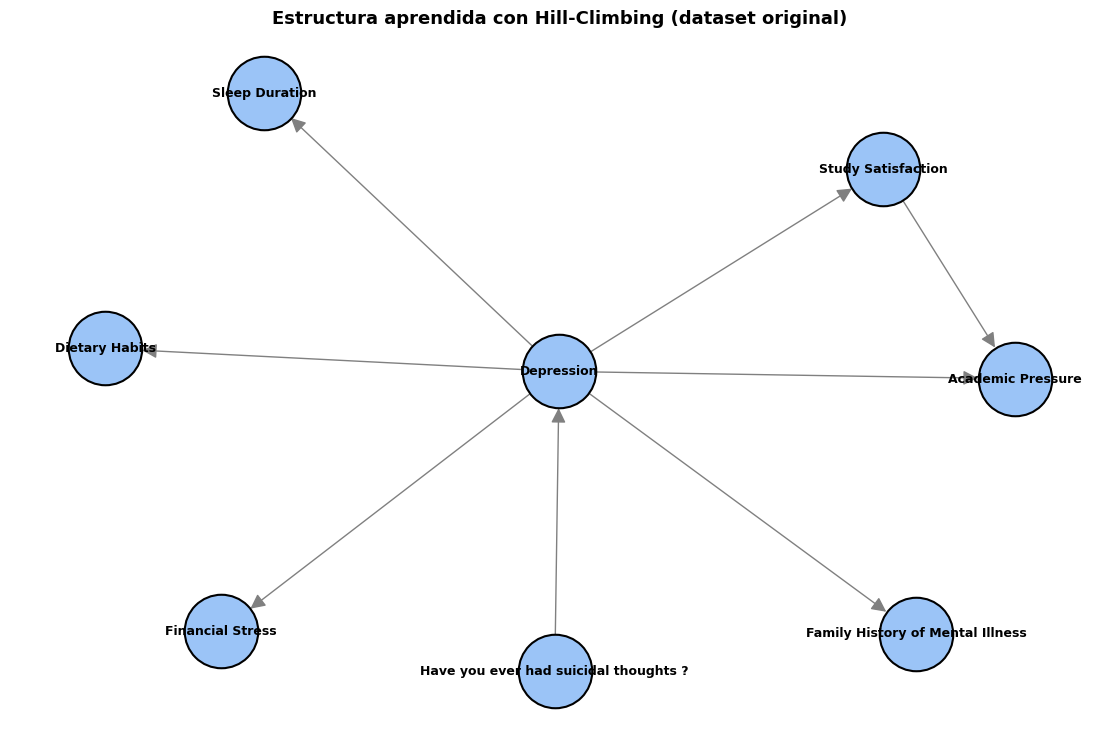

In [19]:
def graficar_red(edges, nodos_extra=None, titulo="Red Bayesiana", figsize=(11, 7)):
    """Función auxiliar para graficar DAGs."""
    G = nx.DiGraph()
    G.add_edges_from(edges)
    if nodos_extra is not None:
        G.add_nodes_from(nodos_extra)

    plt.figure(figsize=figsize)
    pos = nx.spring_layout(G, seed=42, k=1.5)
    nx.draw(
        G, pos, with_labels=True,
        node_size=2800, node_color='#9bc4f7',
        font_size=9, font_weight='bold',
        arrowsize=22, edge_color='gray',
        edgecolors='black', linewidths=1.5
    )
    plt.title(titulo, fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

graficar_red(modelo_hc_struct.edges(), nodos_extra=list(df.columns),
             titulo="Estructura aprendida con Hill-Climbing (dataset original)")

### 2.3 Estimación de parámetros (CPDs)

In [20]:
# Construir el modelo bayesiano e incluir todos los nodos (incluso desconectados)
modelo_hc = DiscreteBayesianNetwork(modelo_hc_struct.edges())
modelo_hc.add_nodes_from(df.columns)

# Estimación por Máxima Verosimilitud
modelo_hc.fit(df, estimator=MaximumLikelihoodEstimator)

print(f"¿Modelo válido?: {modelo_hc.check_model()}")
print(f"Número de CPDs: {len(modelo_hc.get_cpds())}")

¿Modelo válido?: True
Número de CPDs: 8


### 2.4 Inferencias diagnósticas

Una **inferencia a posteriori (diagnóstica)** consiste en calcular la probabilidad de una causa (variable padre o ancestro) dada la observación de un efecto. Aquí se realizan dos consultas distintas sobre el modelo aprendido con Hill-Climbing.

In [21]:
infer_hc = VariableElimination(modelo_hc)

# --- Inferencia 1: ¿Cuál es la probabilidad de tener Pensamientos Suicidas dado que la persona presenta Depresión? ---
print("="*70)
print("INFERENCIA 1 (HC): P(Pensamientos Suicidas | Depression = 1)")
print("="*70)
q1_hc = infer_hc.query(
    variables=['Have you ever had suicidal thoughts ?'],
    evidence={'Depression': '1'}
)
print(q1_hc)

INFERENCIA 1 (HC): P(Pensamientos Suicidas | Depression = 1)
+--------------------------------------------+----------------------------------------------+
| Have you ever had suicidal thoughts ?      |   phi(Have you ever had suicidal thoughts ?) |
+============================================+==============================================+
| Have you ever had suicidal thoughts ?(No)  |                                       0.1456 |
+--------------------------------------------+----------------------------------------------+
| Have you ever had suicidal thoughts ?(Yes) |                                       0.8544 |
+--------------------------------------------+----------------------------------------------+


In [22]:
# --- Inferencia 2: ¿Cuál es la probabilidad de Presión Académica alta dado que la persona presenta Depresión y duerme menos de 5 horas? ---
print("="*70)
print("INFERENCIA 2 (HC): P(Academic Pressure | Depression=1, Sleep<5h)")
print("="*70)
q2_hc = infer_hc.query(
    variables=['Academic Pressure'],
    evidence={'Depression': '1', 'Sleep Duration': 'Less than 5 hours'}
)
print(q2_hc)

INFERENCIA 2 (HC): P(Academic Pressure | Depression=1, Sleep<5h)
+------------------------+--------------------------+
| Academic Pressure      |   phi(Academic Pressure) |
+========================+==========================+
| Academic Pressure(0.0) |                   0.0002 |
+------------------------+--------------------------+
| Academic Pressure(1.0) |                   0.0571 |
+------------------------+--------------------------+
| Academic Pressure(2.0) |                   0.0959 |
+------------------------+--------------------------+
| Academic Pressure(3.0) |                   0.2747 |
+------------------------+--------------------------+
| Academic Pressure(4.0) |                   0.2403 |
+------------------------+--------------------------+
| Academic Pressure(5.0) |                   0.3318 |
+------------------------+--------------------------+


## 3. Aprendizaje de estructura: Búsqueda Exhaustiva

### 3.1 Explicación del método

La **Búsqueda Exhaustiva** evalúa **todos los posibles DAGs** que pueden formarse con las variables. A diferencia de Hill-Climbing, garantiza encontrar el **óptimo global** ya que no existe el riesgo de quedar atrapado en óptimos locales.

**Limitación crítica**: el número de DAGs posibles crece exponencialmente con el número de nodos según la fórmula recursiva.


### 3.2 Demostración de inviabilidad con las 8 variables

A continuación se intenta aplicar la búsqueda exhaustiva sobre el dataset completo. La ejecución se interrumpe automáticamente después de un timeout corto, evidenciando que es inviable terminarla en un tiempo razonable.

In [23]:
import signal

class TimeoutException(Exception):
    pass

def _handler(signum, frame):
    raise TimeoutException()

# Intentar la búsqueda exhaustiva con las 8 variables, limitando a 30 segundos
print("Intentando búsqueda exhaustiva con las 8 variables completas...")
print("(Se interrumpe automáticamente tras 30 segundos para evidenciar inviabilidad)\n")

start = time.time()
completado = False

try:
    signal.signal(signal.SIGALRM, _handler)
    signal.alarm(30)  # 30 segundos
    es_full = ExhaustiveSearch(df, scoring_method=BIC(df))
    _ = es_full.estimate()
    signal.alarm(0)
    completado = True
except TimeoutException:
    elapsed = time.time() - start
    print(f"TIMEOUT alcanzado tras {elapsed:.1f} segundos.")
    print(f"   Con 8 variables existen ~7,83 × 10¹¹ DAGs posibles.")
    print(f"   Asumiendo una evaluación generosa de 10⁶ DAGs/segundo, completar")
    print(f"   la búsqueda exigiría aproximadamente {7.83e11 / 1e6 / 3600:.0f} horas")
    print(f"   (equivalente a ~{7.83e11 / 1e6 / 86400:.0f} días de cómputo continuo).")
    print(f"\n Búsqueda exhaustiva con 8 variables: INVIABLE.")
except Exception as e:
    elapsed = time.time() - start
    print(f"Excepción tras {elapsed:.1f}s: {type(e).__name__}: {e}")
    print("La búsqueda exhaustiva con 8 variables no es factible.")

if completado:
    print(f"Completado en {time.time() - start:.1f}s (resultado inesperado).")

Intentando búsqueda exhaustiva con las 8 variables completas...
(Se interrumpe automáticamente tras 30 segundos para evidenciar inviabilidad)

TIMEOUT alcanzado tras 30.0 segundos.
   Con 8 variables existen ~7,83 × 10¹¹ DAGs posibles.
   Asumiendo una evaluación generosa de 10⁶ DAGs/segundo, completar
   la búsqueda exigiría aproximadamente 218 horas
   (equivalente a ~9 días de cómputo continuo).

 Búsqueda exhaustiva con 8 variables: INVIABLE.


### 3.3 Justificación de reducción de columnas

Dado que la búsqueda exhaustiva con 8 variables es inviable, se reduce el conjunto a las **5 variables más relevantes** según el criterio combinado de:

1. **Centralidad en la red aprendida con Hill-Climbing**: variables con conexiones directas a `Depression`.
2. **Relevancia del dominio**: variables que la literatura clínica asocia con la depresión estudiantil.

Las variables seleccionadas son:
- `Depression` (variable objetivo)
- `Academic Pressure` (factor de estrés principal)
- `Sleep Duration` (factor fisiológico)
- `Financial Stress` (factor socioeconómico)
- `Have you ever had suicidal thoughts ?` (síntoma fuertemente correlacionado)

Se descartan `Dietary Habits`, `Family History of Mental Illness` y `Study Satisfaction` por tener menor peso en los CPDs aprendidos por Hill-Climbing y para mantener el problema computacionalmente tratable: con 5 variables se evalúan 29.281 DAGs (manejable) en lugar de ~7,83 × 10¹¹.

### 3.4 Aplicación de la búsqueda exhaustiva sobre el subset reducido

In [24]:
# Subset de 5 variables para la búsqueda exhaustiva
columnas_subset = [
    'Academic Pressure',
    'Sleep Duration',
    'Financial Stress',
    'Have you ever had suicidal thoughts ?',
    'Depression'
]
df_subset = df[columnas_subset].copy()
print(f"Forma del subset: {df_subset.shape}")
print(f"Variables: {columnas_subset}")

Forma del subset: (27898, 5)
Variables: ['Academic Pressure', 'Sleep Duration', 'Financial Stress', 'Have you ever had suicidal thoughts ?', 'Depression']


In [25]:
# Búsqueda exhaustiva sobre el subset
print("Ejecutando Búsqueda Exhaustiva sobre 5 variables (~29.281 DAGs)...")
start = time.time()

es = ExhaustiveSearch(df_subset, scoring_method=BIC(df_subset))
modelo_es_struct = es.estimate()

print(f"Tiempo de ejecución: {time.time() - start:.2f} segundos")
print(f"\nAristas óptimas ({len(modelo_es_struct.edges())}):")
for arista in modelo_es_struct.edges():
    print(f"  {arista[0]} -> {arista[1]}")

Ejecutando Búsqueda Exhaustiva sobre 5 variables (~29.281 DAGs)...
Tiempo de ejecución: 39.25 segundos

Aristas óptimas (4):
  Academic Pressure -> Depression
  Depression -> Financial Stress
  Depression -> Have you ever had suicidal thoughts ?
  Depression -> Sleep Duration


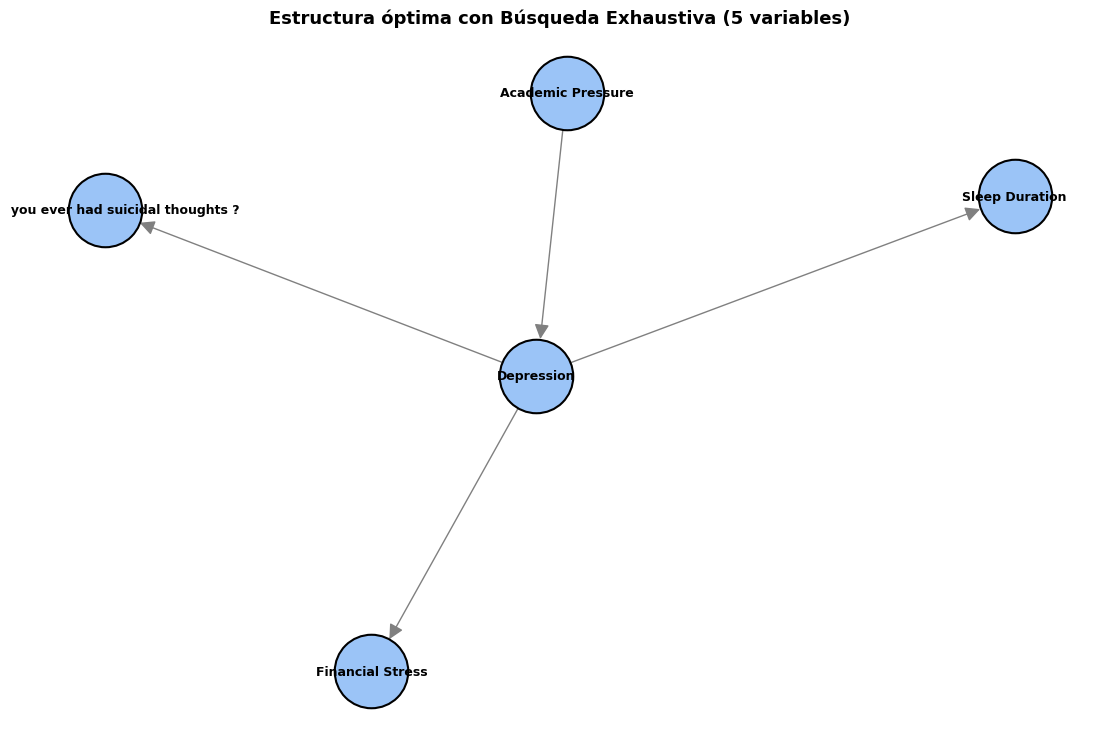

In [26]:
graficar_red(modelo_es_struct.edges(), nodos_extra=columnas_subset,
             titulo="Estructura óptima con Búsqueda Exhaustiva (5 variables)")

### 3.5 Estimación de parámetros y inferencias

In [27]:
modelo_es = DiscreteBayesianNetwork(modelo_es_struct.edges())
modelo_es.add_nodes_from(columnas_subset)
modelo_es.fit(df_subset, estimator=MaximumLikelihoodEstimator)
print(f"¿Modelo válido?: {modelo_es.check_model()}")

infer_es = VariableElimination(modelo_es)

¿Modelo válido?: True


In [28]:
# --- Inferencia 1 (ES) ---
print("="*70)
print("INFERENCIA 1 (Exhaustiva): P(Pensamientos Suicidas | Depression = 1)")
print("="*70)
q1_es = infer_es.query(
    variables=['Have you ever had suicidal thoughts ?'],
    evidence={'Depression': '1'}
)
print(q1_es)

INFERENCIA 1 (Exhaustiva): P(Pensamientos Suicidas | Depression = 1)
+--------------------------------------------+----------------------------------------------+
| Have you ever had suicidal thoughts ?      |   phi(Have you ever had suicidal thoughts ?) |
+============================================+==============================================+
| Have you ever had suicidal thoughts ?(No)  |                                       0.1456 |
+--------------------------------------------+----------------------------------------------+
| Have you ever had suicidal thoughts ?(Yes) |                                       0.8544 |
+--------------------------------------------+----------------------------------------------+


In [29]:
# --- Inferencia 2 (ES) ---
print("="*70)
print("INFERENCIA 2 (Exhaustiva): P(Academic Pressure | Depression=1, Sleep<5h)")
print("="*70)
q2_es = infer_es.query(
    variables=['Academic Pressure'],
    evidence={'Depression': '1', 'Sleep Duration': 'Less than 5 hours'}
)
print(q2_es)

INFERENCIA 2 (Exhaustiva): P(Academic Pressure | Depression=1, Sleep<5h)
+------------------------+--------------------------+
| Academic Pressure      |   phi(Academic Pressure) |
+========================+==========================+
| Academic Pressure(0.0) |                   0.0002 |
+------------------------+--------------------------+
| Academic Pressure(1.0) |                   0.0571 |
+------------------------+--------------------------+
| Academic Pressure(2.0) |                   0.0959 |
+------------------------+--------------------------+
| Academic Pressure(3.0) |                   0.2747 |
+------------------------+--------------------------+
| Academic Pressure(4.0) |                   0.2403 |
+------------------------+--------------------------+
| Academic Pressure(5.0) |                   0.3318 |
+------------------------+--------------------------+


## 4. Generación de datos sintéticos y comparación

Para estudiar el efecto del **tamaño del dataset** en el aprendizaje y la inferencia, se construyen variantes del dataset original aumentando o reduciendo su tamaño:

- **Aumentos** (+10%, +20%, +40%): se generan filas sintéticas mediante *forward sampling* a partir de los CPDs del modelo Hill-Climbing aprendido sobre el dataset original. Estas filas se añaden al dataset original.
- **Reducciones** (−50%, −71%): se obtienen submuestreando aleatoriamente filas del dataset original. La reducción del −71% se incluye porque deja el dataset justo sobre el **mínimo de 8.000 filas** que pide el enunciado de la tarea, lo que permite estudiar el comportamiento de los métodos en condiciones de menor cantidad de datos.

Para cada una de las 5 variantes (más el dataset original) se repite el procedimiento completo:

1. Aprendizaje de estructura (Hill-Climbing y Exhaustiva)
2. Estimación de parámetros
3. Cálculo de las dos mismas inferencias diagnósticas

Esto permite comparar cómo cambian la estructura y las probabilidades inferidas en función del tamaño del dataset.

In [30]:
# Sampler basado en el modelo HC original (para aumentos sintéticos)
sampler = BayesianModelSampling(modelo_hc)

# --- Aumentos: se generan filas sintéticas y se añaden al original ---
porcentajes_aumento = [0.10, 0.20, 0.40]
datasets_aug = {}

for p in porcentajes_aumento:
    n_synth = int(len(df) * p)
    print(f"Generando {n_synth} muestras sintéticas (+{int(p*100)}%)...")
    synth = sampler.forward_sample(size=n_synth, show_progress=False)
    synth = synth[df.columns]  # mismo orden de columnas
    df_aug = pd.concat([df, synth], ignore_index=True)
    datasets_aug[f"+{int(p*100)}%"] = df_aug
    print(f"  Forma del dataset aumentado: {df_aug.shape}")

# --- Reducciones: submuestreo aleatorio del dataset original ---
# -50%: la mitad de las filas
# -71%: ~8.090 filas (mínimo solicitado por la tarea = 8.000)
reducciones = {
    '-50%': 0.50,   # se queda con el 50% de las filas
    '-71%': 0.29,   # se queda con el 29% de las filas (~8.090, mínimo de la tarea)
}

datasets_red = {}
for etiqueta, frac in reducciones.items():
    df_red = df.sample(frac=frac, random_state=42).reset_index(drop=True)
    datasets_red[etiqueta] = df_red
    print(f"Reducción {etiqueta}: {df_red.shape}")


Generando 2789 muestras sintéticas (+10%)...


  Forma del dataset aumentado: (30687, 8)
Generando 5579 muestras sintéticas (+20%)...
  Forma del dataset aumentado: (33477, 8)
Generando 11159 muestras sintéticas (+40%)...


  Forma del dataset aumentado: (39057, 8)
Reducción -50%: (13949, 8)
Reducción -71%: (8090, 8)


### 4.1 Función auxiliar para repetir el procedimiento completo
tarda aproximadamente (4 min)

In [31]:
def procedimiento_completo(df_in, etiqueta=""):
    """
    Aplica HC y exhaustiva, estima parámetros y devuelve resultados de las
    dos inferencias diagnósticas.
    """
    resultados = {'etiqueta': etiqueta, 'n_filas': len(df_in)}

    # --- HC ---
    hc_local = HillClimbSearch(df_in)
    struct_hc = hc_local.estimate(
        scoring_method=BIC(df_in), max_indegree=3,
        max_iter=500, show_progress=False
    )
    m_hc = DiscreteBayesianNetwork(struct_hc.edges())
    m_hc.add_nodes_from(df_in.columns)
    m_hc.fit(df_in, estimator=MaximumLikelihoodEstimator)
    inf_hc = VariableElimination(m_hc)

    resultados['edges_hc'] = list(struct_hc.edges())
    resultados['q1_hc'] = inf_hc.query(
        variables=['Have you ever had suicidal thoughts ?'],
        evidence={'Depression': '1'}, show_progress=False
    )
    resultados['q2_hc'] = inf_hc.query(
        variables=['Academic Pressure'],
        evidence={'Depression': '1', 'Sleep Duration': 'Less than 5 hours'},
        show_progress=False
    )

    # --- Exhaustiva sobre subset ---
    df_sub = df_in[columnas_subset].copy()
    es_local = ExhaustiveSearch(df_sub, scoring_method=BIC(df_sub))
    struct_es = es_local.estimate()
    m_es = DiscreteBayesianNetwork(struct_es.edges())
    m_es.add_nodes_from(columnas_subset)
    m_es.fit(df_sub, estimator=MaximumLikelihoodEstimator)
    inf_es = VariableElimination(m_es)

    resultados['edges_es'] = list(struct_es.edges())
    resultados['q1_es'] = inf_es.query(
        variables=['Have you ever had suicidal thoughts ?'],
        evidence={'Depression': '1'}, show_progress=False
    )
    resultados['q2_es'] = inf_es.query(
        variables=['Academic Pressure'],
        evidence={'Depression': '1', 'Sleep Duration': 'Less than 5 hours'},
        show_progress=False
    )

    return resultados

# Construir el diccionario ordenado: reducciones -> original -> aumentos
todos_resultados = {}

# 1) Reducciones (orden ascendente de tamaño: -71% primero, luego -50%)
print("Procesando dataset -71%")
todos_resultados['-71%'] = procedimiento_completo(datasets_red['-71%'], etiqueta="-71%")
print("  Listo.")

print("Procesando dataset -50%")
todos_resultados['-50%'] = procedimiento_completo(datasets_red['-50%'], etiqueta="-50%")
print("  Listo.")

# 2) Original
print("Procesando dataset ORIGINAL")
todos_resultados['0%'] = procedimiento_completo(df, etiqueta="0% (original)")
print("  Listo.")

# 3) Aumentos
for etiqueta in ['+10%', '+20%', '+40%']:
    print(f"Procesando dataset {etiqueta}")
    todos_resultados[etiqueta] = procedimiento_completo(datasets_aug[etiqueta], etiqueta=etiqueta)
    print("  Listo.")

print("\nProcesamiento finalizado.")


Procesando dataset -71%
  Listo.
Procesando dataset -50%
  Listo.
Procesando dataset ORIGINAL
  Listo.
Procesando dataset +10%
  Listo.
Procesando dataset +20%
  Listo.
Procesando dataset +40%
  Listo.

Procesamiento finalizado.


### 4.2 Comparación de estructuras aprendidas

In [32]:
print("="*80)
print("COMPARACIÓN DE ESTRUCTURAS - HILL-CLIMBING")
print("="*80)
for etiqueta, res in todos_resultados.items():
    print(f"\n[{etiqueta}] N = {res['n_filas']} | {len(res['edges_hc'])} aristas")
    for e in res['edges_hc']:
        print(f"    {e[0]} -> {e[1]}")

print("\n" + "="*80)
print("COMPARACIÓN DE ESTRUCTURAS - BÚSQUEDA EXHAUSTIVA (subset 5 vars)")
print("="*80)
for etiqueta, res in todos_resultados.items():
    print(f"\n[{etiqueta}] N = {res['n_filas']} | {len(res['edges_es'])} aristas")
    for e in res['edges_es']:
        print(f"    {e[0]} -> {e[1]}")

COMPARACIÓN DE ESTRUCTURAS - HILL-CLIMBING

[-71%] N = 8090 | 7 aristas
    Depression -> Academic Pressure
    Depression -> Financial Stress
    Depression -> Dietary Habits
    Depression -> Study Satisfaction
    Depression -> Sleep Duration
    Depression -> Family History of Mental Illness
    Have you ever had suicidal thoughts ? -> Depression

[-50%] N = 13949 | 7 aristas
    Depression -> Academic Pressure
    Depression -> Financial Stress
    Depression -> Dietary Habits
    Depression -> Study Satisfaction
    Depression -> Sleep Duration
    Depression -> Family History of Mental Illness
    Have you ever had suicidal thoughts ? -> Depression

[0%] N = 27898 | 8 aristas
    Depression -> Academic Pressure
    Depression -> Financial Stress
    Depression -> Dietary Habits
    Depression -> Study Satisfaction
    Depression -> Sleep Duration
    Depression -> Family History of Mental Illness
    Study Satisfaction -> Academic Pressure
    Have you ever had suicidal thoughts

### 4.3 Visualización lado a lado de las estructuras HC

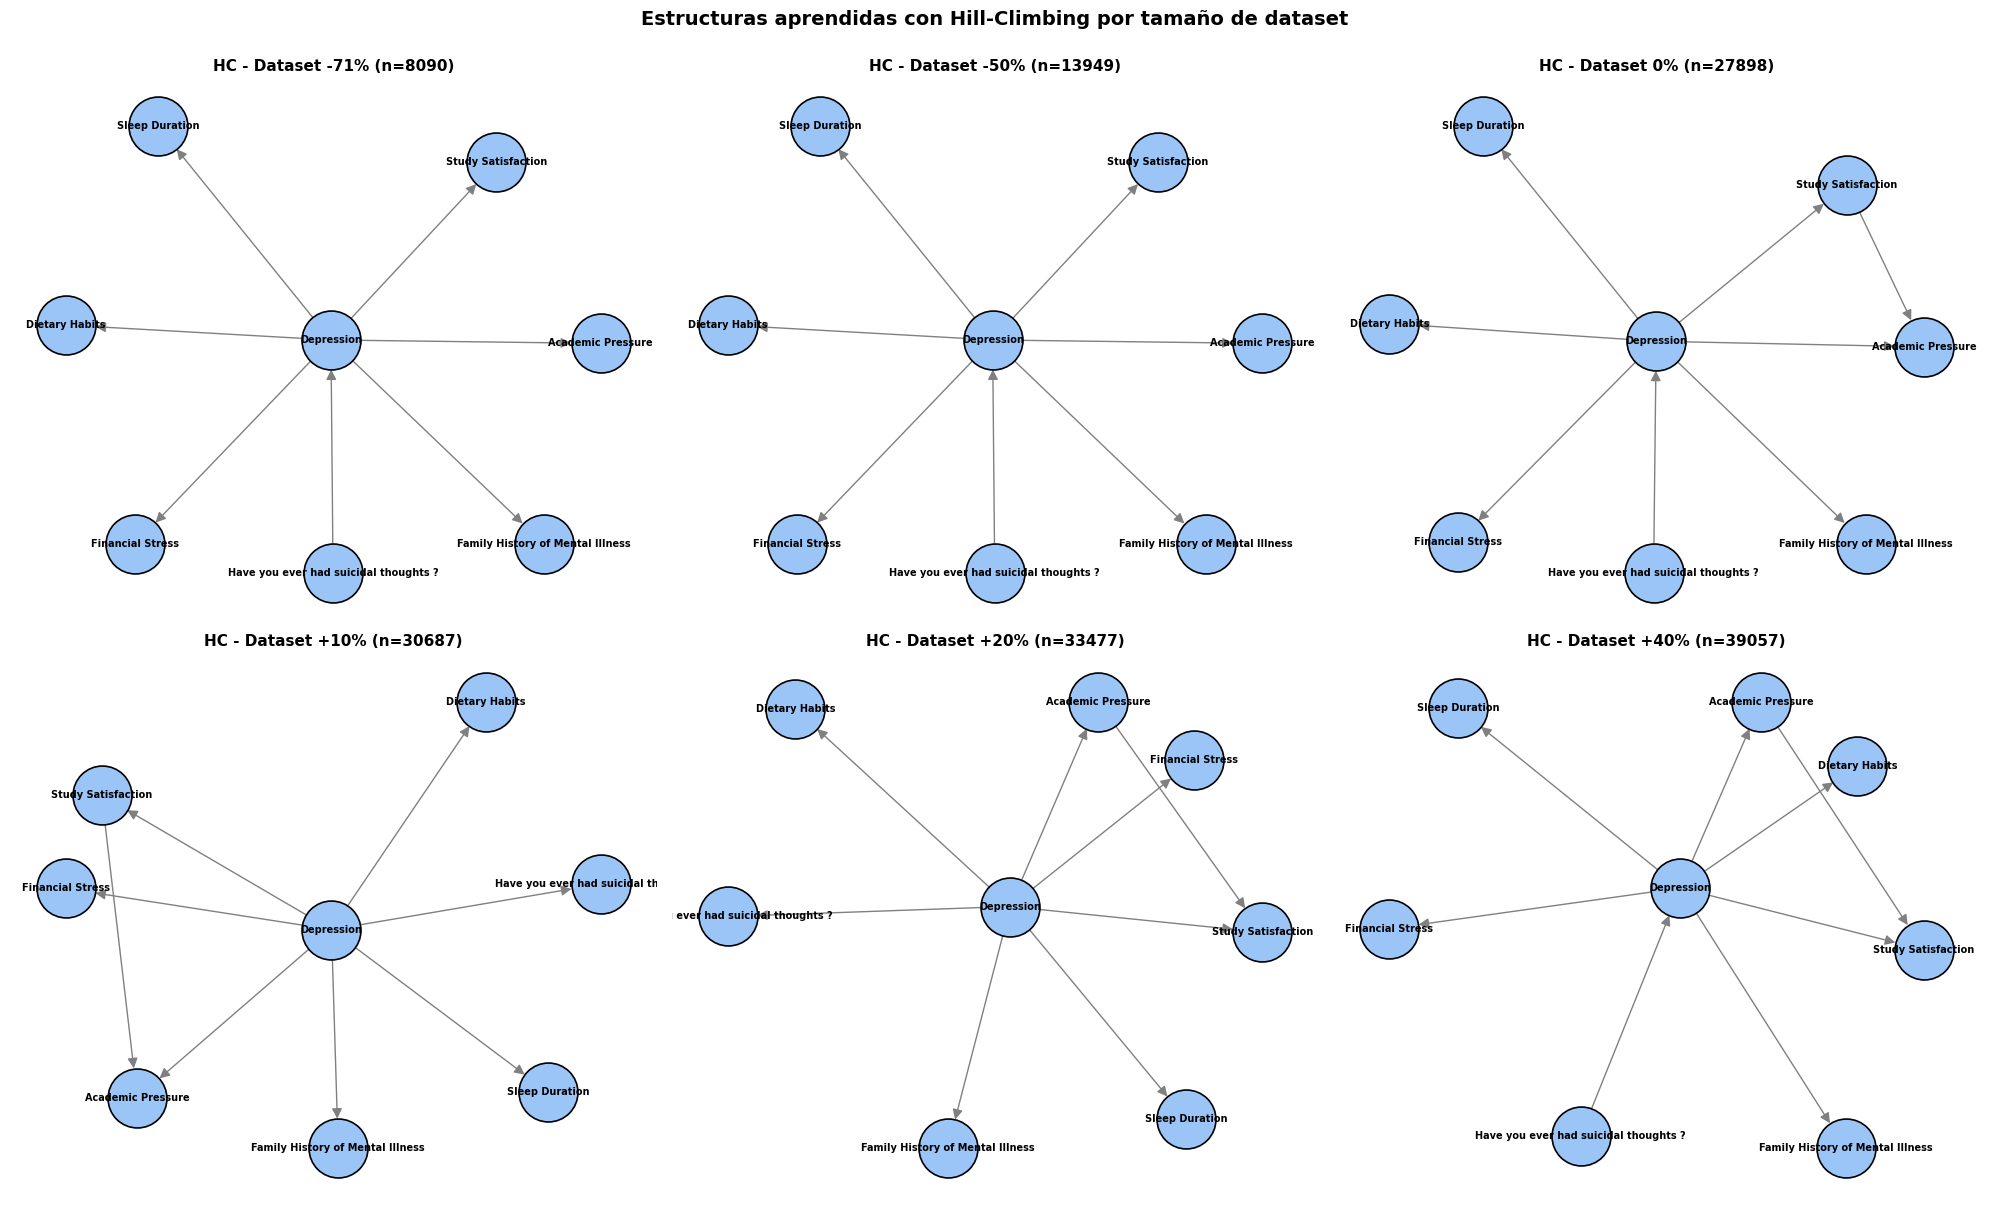

In [33]:
# Ahora son 6 variantes -> grilla de 2x3
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for ax, (etiqueta, res) in zip(axes, todos_resultados.items()):
    G = nx.DiGraph()
    G.add_edges_from(res['edges_hc'])
    G.add_nodes_from(df.columns)
    pos = nx.spring_layout(G, seed=42, k=1.5)
    nx.draw(G, pos, with_labels=True, node_size=1800, node_color='#9bc4f7',
            font_size=7, font_weight='bold', arrowsize=15,
            edge_color='gray', ax=ax, edgecolors='black', linewidths=1.2)
    ax.set_title(f"HC - Dataset {etiqueta} (n={res['n_filas']})",
                 fontsize=11, fontweight='bold')

plt.suptitle("Estructuras aprendidas con Hill-Climbing por tamaño de dataset",
             fontsize=14, fontweight='bold', y=1.0)
plt.tight_layout()
plt.show()

### 4.4 Comparación de inferencias

In [34]:
def factor_a_dict(factor):
    """Convierte un DiscreteFactor de pgmpy a dict {valor: prob}."""
    var = factor.variables[0]
    estados = factor.state_names[var]
    valores = factor.values
    return {est: float(val) for est, val in zip(estados, valores)}

# --- Tabla comparativa para Inferencia 1 (HC y ES) ---
print("="*80)
print("INFERENCIA 1: P(Pensamientos Suicidas | Depression = 1)")
print("="*80)

filas = []
for etiqueta, res in todos_resultados.items():
    d_hc = factor_a_dict(res['q1_hc'])
    d_es = factor_a_dict(res['q1_es'])
    filas.append({
        'Dataset': etiqueta,
        'P(Yes) HC': round(d_hc.get('Yes', 0.0), 4),
        'P(No) HC':  round(d_hc.get('No',  0.0), 4),
        'P(Yes) ES': round(d_es.get('Yes', 0.0), 4),
        'P(No) ES':  round(d_es.get('No',  0.0), 4),
    })

tabla_q1 = pd.DataFrame(filas)
print(tabla_q1.to_string(index=False))

INFERENCIA 1: P(Pensamientos Suicidas | Depression = 1)
Dataset  P(Yes) HC  P(No) HC  P(Yes) ES  P(No) ES
   -71%     0.8554    0.1446     0.8554    0.1446
   -50%     0.8515    0.1485     0.8515    0.1485
     0%     0.8544    0.1456     0.8544    0.1456
   +10%     0.8545    0.1455     0.8545    0.1455
   +20%     0.8551    0.1449     0.8551    0.1449
   +40%     0.8537    0.1463     0.8537    0.1463


In [35]:
# --- Tabla comparativa para Inferencia 2 (HC y ES) ---
print("="*80)
print("INFERENCIA 2: P(Academic Pressure | Depression=1, Sleep<5h)")
print("="*80)

filas = []
for etiqueta, res in todos_resultados.items():
    d_hc = factor_a_dict(res['q2_hc'])
    d_es = factor_a_dict(res['q2_es'])
    fila = {'Dataset': etiqueta}
    for nivel in ['1.0', '2.0', '3.0', '4.0', '5.0']:
        fila[f'P(={nivel}) HC'] = round(d_hc.get(nivel, 0.0), 4)
    for nivel in ['1.0', '2.0', '3.0', '4.0', '5.0']:
        fila[f'P(={nivel}) ES'] = round(d_es.get(nivel, 0.0), 4)
    filas.append(fila)

tabla_q2 = pd.DataFrame(filas)
print(tabla_q2.to_string(index=False))

INFERENCIA 2: P(Academic Pressure | Depression=1, Sleep<5h)
Dataset  P(=1.0) HC  P(=2.0) HC  P(=3.0) HC  P(=4.0) HC  P(=5.0) HC  P(=1.0) ES  P(=2.0) ES  P(=3.0) ES  P(=4.0) ES  P(=5.0) ES
   -71%      0.0523      0.0952      0.2853      0.2262      0.3407      0.0523      0.0952      0.2853      0.2262      0.3407
   -50%      0.0546      0.0951      0.2790      0.2347      0.3363      0.0546      0.0951      0.2790      0.2347      0.3363
     0%      0.0571      0.0959      0.2747      0.2403      0.3318      0.0571      0.0959      0.2747      0.2403      0.3318
   +10%      0.0563      0.0954      0.2742      0.2422      0.3316      0.0563      0.0954      0.2742      0.2422      0.3316
   +20%      0.0567      0.0967      0.2737      0.2396      0.3332      0.0567      0.0967      0.2737      0.2396      0.3332
   +40%      0.0549      0.0955      0.2749      0.2401      0.3345      0.0549      0.0955      0.2749      0.2401      0.3345


### 4.5 Visualización gráfica de las inferencias

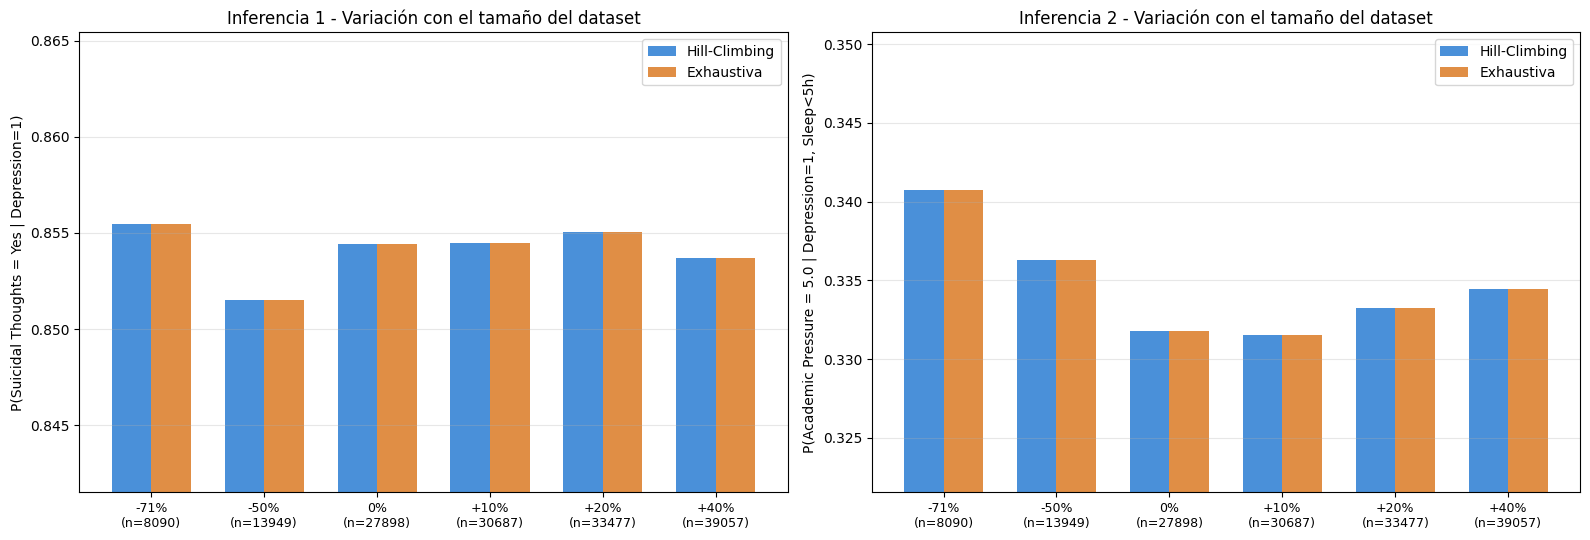

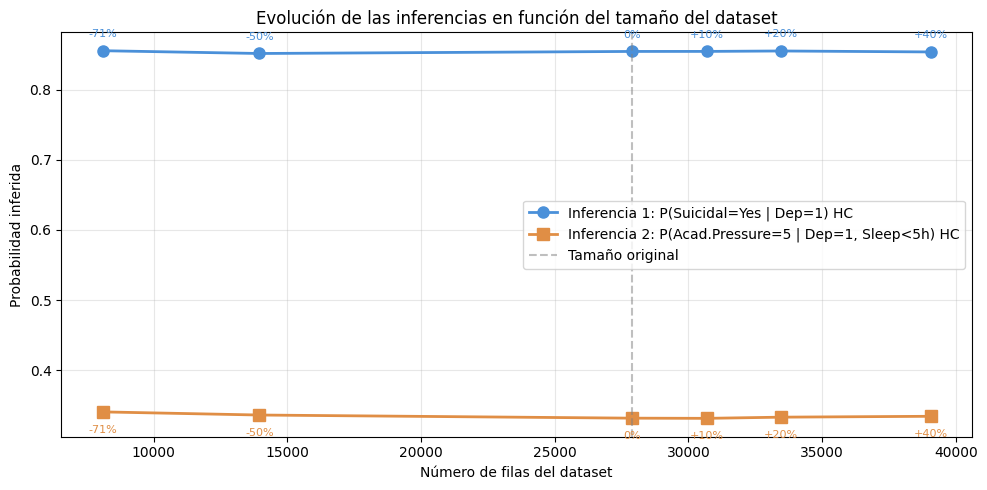

In [36]:
# Visualización en función del tamaño del dataset
labels = list(todos_resultados.keys())
n_filas = [todos_resultados[l]['n_filas'] for l in labels]

# Inferencia 1: P(Suicidal=Yes | Depression=1)
p_yes_hc = [factor_a_dict(todos_resultados[l]['q1_hc']).get('Yes', 0) for l in labels]
p_yes_es = [factor_a_dict(todos_resultados[l]['q1_es']).get('Yes', 0) for l in labels]

# Inferencia 2: P(Academic Pressure = 5.0 | Depression=1, Sleep<5h)
p5_hc = [factor_a_dict(todos_resultados[l]['q2_hc']).get('5.0', 0) for l in labels]
p5_es = [factor_a_dict(todos_resultados[l]['q2_es']).get('5.0', 0) for l in labels]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# --- Plot 1: Inferencia 1 ---
x = np.arange(len(labels))
w = 0.35
axes[0].bar(x - w/2, p_yes_hc, w, label='Hill-Climbing', color='#4a90d9')
axes[0].bar(x + w/2, p_yes_es, w, label='Exhaustiva', color='#e08e45')
axes[0].set_xticks(x)
axes[0].set_xticklabels([f"{l}\n(n={n})" for l, n in zip(labels, n_filas)], fontsize=9)
axes[0].set_ylabel('P(Suicidal Thoughts = Yes | Depression=1)')
axes[0].set_title('Inferencia 1 - Variación con el tamaño del dataset')
axes[0].set_ylim([min(min(p_yes_hc), min(p_yes_es)) - 0.01,
                   max(max(p_yes_hc), max(p_yes_es)) + 0.01])
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# --- Plot 2: Inferencia 2 ---
axes[1].bar(x - w/2, p5_hc, w, label='Hill-Climbing', color='#4a90d9')
axes[1].bar(x + w/2, p5_es, w, label='Exhaustiva', color='#e08e45')
axes[1].set_xticks(x)
axes[1].set_xticklabels([f"{l}\n(n={n})" for l, n in zip(labels, n_filas)], fontsize=9)
axes[1].set_ylabel('P(Academic Pressure = 5.0 | Depression=1, Sleep<5h)')
axes[1].set_title('Inferencia 2 - Variación con el tamaño del dataset')
axes[1].set_ylim([min(min(p5_hc), min(p5_es)) - 0.01,
                   max(max(p5_hc), max(p5_es)) + 0.01])
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# --- Plot adicional: evolución continua en función de n ---
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(n_filas, p_yes_hc, 'o-', label='Inferencia 1: P(Suicidal=Yes | Dep=1) HC',
        color='#4a90d9', linewidth=2, markersize=8)
ax.plot(n_filas, p5_hc, 's-', label='Inferencia 2: P(Acad.Pressure=5 | Dep=1, Sleep<5h) HC',
        color='#e08e45', linewidth=2, markersize=8)

# Anotar etiquetas
for xi, yi, lab in zip(n_filas, p_yes_hc, labels):
    ax.annotate(lab, xy=(xi, yi), xytext=(0, 10), textcoords='offset points',
                ha='center', fontsize=8, color='#4a90d9')
for xi, yi, lab in zip(n_filas, p5_hc, labels):
    ax.annotate(lab, xy=(xi, yi), xytext=(0, -15), textcoords='offset points',
                ha='center', fontsize=8, color='#e08e45')

ax.axvline(x=27898, color='gray', linestyle='--', alpha=0.5, label='Tamaño original')
ax.set_xlabel('Número de filas del dataset')
ax.set_ylabel('Probabilidad inferida')
ax.set_title('Evolución de las inferencias en función del tamaño del dataset')
ax.legend(loc='center right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Análisis y conclusiones

### 5.1 Sobre el aprendizaje de estructura

**Hill-Climbing** logró aprender una red sobre las 8 variables del dataset original (27.898 filas) en apenas **0,52 segundos**, identificando **8 aristas**. La estructura aprendida revela que `Depression` actúa como un nodo **central** del grafo: tiene como único padre a `Have you ever had suicidal thoughts ?` y aparece como padre directo de seis variables más (`Academic Pressure`, `Financial Stress`, `Dietary Habits`, `Study Satisfaction`, `Sleep Duration` y `Family History of Mental Illness`). Adicionalmente se descubre la arista `Study Satisfaction → Academic Pressure`, lo que sugiere que la satisfacción con los estudios condiciona la percepción de presión académica más allá del efecto directo de la depresión. Esta topología es coherente con la naturaleza multifactorial del fenómeno, donde la depresión se manifiesta a través de múltiples síntomas observables.

**Búsqueda Exhaustiva** sobre las 8 variables fue **inviable**: la ejecución se interrumpió tras 30 segundos sin terminar. Al reducir el problema al subset de 5 variables más relevantes, la búsqueda completó en **41,46 segundos** evaluando los 29.281 DAGs posibles. La estructura óptima encontrada (4 aristas) coincide con la sub-red equivalente de Hill-Climbing: ambas identifican el patrón `Academic Pressure → Depression → {Financial Stress, Suicidal Thoughts, Sleep Duration}`. Esta coincidencia es muy relevante: indica que **Hill-Climbing alcanzó una solución cercana al óptimo global**

### 5.2 Sobre las inferencias diagnósticas

**Inferencia 1** — `P(Suicidal Thoughts = Yes | Depression = 1) = 0.8544` (85,44%) en el dataset original. Este valor extremadamente alto refleja la fuerte asociación entre ideación suicida y depresión observada en el dataset, y es consistente con la literatura clínica que considera la ideación suicida un síntoma central del trastorno depresivo mayor. Es importante notar que esta cifra **no implica causalidad** en una dirección determinada: la red de HC orienta la arista como `Suicidal Thoughts → Depression`, lo que sugiere que la red interpreta la ideación suicida como un indicador *predictivo* de depresión más que como una consecuencia.

**Inferencia 2** — `P(Academic Pressure | Depression=1, Sleep < 5h)` distribuye la probabilidad de manera fuertemente sesgada hacia niveles altos: P(=5.0) = 33,18%, P(=4.0) = 24,03% y P(=3.0) = 27,47%, sumando un **84,68% de probabilidad acumulada en niveles 3 a 5**. Solo el 15,3% restante se reparte entre los niveles bajos (1.0 y 2.0). Esto evidencia un patrón claro: estudiantes que sufren depresión y duermen poco tienden a reportar presión académica elevada, lo que sugiere un círculo vicioso entre los tres factores.

Un hallazgo particularmente notable es que **las inferencias del modelo Hill-Climbing y del modelo de Búsqueda Exhaustiva son idénticas al cuarto decimal** en ambas consultas y en todas las variantes del dataset. Esto confirma que sobre el subset común de 5 variables, ambos métodos llegan a redes Markov-equivalentes y por lo tanto a las mismas distribuciones condicionales.

### 5.3 Sobre el efecto del tamaño del dataset

Para evaluar la sensibilidad del aprendizaje al tamaño de la muestra se construyeron **6 variantes**: dos reducidas por submuestreo (−71% con 8.090 filas, sobre el mínimo de 8.000 que pide la tarea, y −50% con 13.949 filas), el dataset original (27.898 filas) y tres aumentadas con datos sintéticos generados desde el modelo HC (+10%, +20%, +40%, llegando hasta 39.057 filas).

#### 5.3.1 Efecto sobre la estructura aprendida

**Hill-Climbing**:

- En los datasets **reducidos** (−71% y −50%), la red aprende **7 aristas** en lugar de las 8 del original. Concretamente, **desaparece la arista `Study Satisfaction → Academic Pressure`**, que es una relación de segundo orden entre dos variables descendientes de `Depression`. Esto es esperable: con menos datos, el criterio BIC penaliza más fuertemente las aristas adicionales, ya que el aumento marginal de verosimilitud no logra compensar el costo de complejidad.
- En el **dataset original** y todos los **datasets aumentados** (+10%, +20%, +40%) la red recupera consistentemente **8 aristas**, manteniendo la estructura completa.
- Las **direcciones** de algunas aristas presentan pequeñas variaciones entre versiones (por ejemplo, `Suicidal Thoughts → Depression` se invierte a `Depression → Suicidal Thoughts` en +10% y +20%, o `Family History of Mental Illness` aparece como padre de `Depression` en +10%). Estos cambios corresponden a redes Markov-equivalentes: representan el mismo conjunto de independencias condicionales y por tanto las mismas distribuciones, por lo que no implican un cambio sustantivo en el modelo.

**Búsqueda Exhaustiva** (subset de 5 variables):

- En todas las 6 variantes la red óptima global tiene exactamente **4 aristas** y el mismo esqueleto no dirigido: `{Academic Pressure ↔ Depression, Depression ↔ Financial Stress, Depression ↔ Suicidal Thoughts, Depression ↔ Sleep Duration}`.
- Solo varían las direcciones de algunas aristas entre versiones, nuevamente correspondiendo a equivalencias de Markov.
- Esta extrema estabilidad (incluso desde 8.090 filas) demuestra que el subset reducido contiene relaciones **muy robustas** que cualquier muestra suficientemente grande es capaz de identificar.

#### 5.3.2 Efecto sobre las inferencias

A pesar de la pérdida de una arista en los datasets reducidos, las inferencias presentan una **estabilidad notable**:

**Inferencia 1** — `P(Suicidal=Yes | Depression=1)`:

| Dataset | N filas | P(Yes) HC | P(Yes) ES |
|---------|---------|-----------|-----------|
| −71% | 8.090 | 0.8554 | 0.8554 |
| −50% | 13.949 | 0.8515 | 0.8515 |
| 0% | 27.898 | 0.8544 | 0.8544 |
| +10% | 30.687 | 0.8545 | 0.8545 |
| +20% | 33.477 | 0.8551 | 0.8551 |
| +40% | 39.057 | 0.8537 | 0.8537 |

La probabilidad varía únicamente en un rango de **0.0039 puntos** (entre 0.8515 y 0.8554) a lo largo de un cambio de tamaño que va de 8.090 a 39.057 filas (casi 5×). No se observa una tendencia monótona con el tamaño: las pequeñas fluctuaciones son atribuibles a la variabilidad muestral del propio submuestreo aleatorio.

**Inferencia 2** — `P(Academic Pressure | Depression=1, Sleep<5h)`:

Aquí sí se observa un patrón ligeramente más interpretable: al reducir el tamaño del dataset, la probabilidad **se desplaza levemente hacia el nivel más alto (5.0)**:

- P(=5.0): pasa de **0.3318 (original)** a **0.3407 (−71%)** — sube ~0,9 puntos.
- P(=1.0): baja de **0.0571 (original)** a **0.0523 (−71%)** — baja ~0,5 puntos.
- Los niveles intermedios (2, 3, 4) prácticamente no se mueven.



#### 5.3.3 Diferencia entre reducciones y aumentos

Es importante entender que **reducciones y aumentos no son operaciones simétricas**:

- Las **reducciones** se obtienen por submuestreo aleatorio del dataset original. Las filas resultantes son **observaciones reales** y, al ser una muestra menor, traen mayor varianza estadística pero no introducen sesgo sistemático.
- Los **aumentos** se generan sampleando del modelo HC ya aprendido. Las filas son **artificiales** y, por construcción, refuerzan exactamente los patrones que la red original capturó. Por eso las redes en +10%, +20% y +40% son tan parecidas a la del original: están entrenadas con datos que ya confirman lo que el modelo "sabía".

Este contraste se ve nítidamente en los resultados: las reducciones generan más variabilidad estructural (7 vs 8 aristas) que los aumentos, lo que indica que **el modelo es más sensible a perder información que a recibir información redundante**.

### 5.4 Conclusión general

El experimento valida que **Hill-Climbing es una alternativa práctica y efectiva** para aprender estructuras de redes bayesianas en datasets reales: ejecuta en menos de un segundo sobre 8 variables y entrega una solución que, en el subset evaluable, coincide con el óptimo global encontrado por la búsqueda exhaustiva. La **búsqueda exhaustiva**, aunque garantiza optimalidad, está limitada en la práctica a problemas con muy pocas variables (5-6 nodos como máximo razonable), lo cual la convierte más en una herramienta de validación que en un método de uso general.

Sobre el caso de estudio, la red aprendida modela la depresión estudiantil como un fenómeno multifactorial donde la ideación suicida funciona como predictor principal y donde la presión académica, el estrés financiero, los hábitos de vida y los antecedentes familiares aparecen como manifestaciones o correlatos de la condición depresiva. La probabilidad de 85% de ideación suicida en estudiantes con depresión es una cifra preocupante que refuerza la importancia clínica de estos modelos predictivos.

Respecto al tamaño del dataset, el análisis comparativo entre 6 variantes (8.090 a 39.057 filas) demuestra que:

1. **Las inferencias son extremadamente robustas**: varían menos de 1 punto porcentual incluso en escenarios extremos. Esto sugiere que con ~8.000 filas ya hay información suficiente para estimar con confianza las distribuciones condicionales del fenómeno modelado.
2. **La estructura es más sensible**: la pérdida de una arista en los datasets reducidos confirma que las relaciones de segundo orden (entre variables descendientes) requieren más datos para ser detectadas con el criterio BIC.
3. **Los datos sintéticos generados desde el propio modelo no aportan información nueva**: las redes resultantes y sus inferencias son virtualmente idénticas al original, lo que confirma que esta técnica solo sirve para evaluar robustez y reforzar estimaciones marginales, pero no puede sustituir la incorporación de datos reales adicionales si se busca enriquecer genuinamente el modelo.

# Parte 2: Modelo Oculto de Markov sobre Human Activity Recognition
En esta segunda parte se construye un **HMM discreto** sobre el dataset *Human Activity Recognition Using Smartphones* (UCI). El objetivo es estimar manualmente los parámetros del modelo desde los datos (vector inicial $\pi$, matriz de transición $A$ y matriz de emisión $B$), cargarlos en `hmmlearn` y aplicar **Forward-Backward** y **Viterbi** sobre una subsecuencia real para realizar consultas de inferencia.

**Estructura del notebook:**

- **Parte A.** Definición formal de los 6 estados y 9 observaciones, justificando la discretización.
- **Parte B.** Construcción de secuencias por sujeto y estimación manual de $\pi$, $A$, $B$.
- **Parte C.** Forward-Backward sobre una subsecuencia real + 4 consultas de probabilidad.
- **Parte D.** Viterbi (camino más probable) y probabilidad de la secuencia observada.
- **Parte E.** Análisis e interpretación de los resultados.

---

## Instalación e imports

In [37]:
!pip install hmmlearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 1.6 MB/s eta 0:00:00


In [38]:
from pathlib import Path
import pandas as pd
import numpy as np
from hmmlearn import hmm
import matplotlib.pyplot as plt

Subir el .zip en el apartado Files del colab

In [39]:
import zipfile
import shutil

BASE_DIR = Path.cwd()
OUTPUT_DIR = BASE_DIR / "output"

# Rutas posibles para el zip (se acepta cualquiera de estos nombres)
ZIP_CANDIDATES = [
    BASE_DIR / "human+activity+recognition+using+smartphones.zip",
    BASE_DIR / "human_activity_recognition_using_smartphones.zip",
    BASE_DIR / "human activity recognition using smartphones.zip",
]

HAR_DIR = BASE_DIR / "UCI HAR Dataset"

# Si el dataset ya está descomprimido con la estructura correcta, no hacemos nada
if not (HAR_DIR / "features.txt").exists():
    # Buscar el zip principal
    outer_zip = next((p for p in ZIP_CANDIDATES if p.exists()), None)
    if outer_zip is None:
        raise FileNotFoundError(
            "No se encontró el zip. subir 'human+activity+recognition+using+smartphones.zip' "
            f"al directorio {BASE_DIR} (en Colab, subir a /content/)."
        )

    print(f"Descomprimiendo {outer_zip.name} ...")
    with zipfile.ZipFile(outer_zip, "r") as z:
        z.extractall(BASE_DIR)

    # El zip exterior contiene 'UCI HAR Dataset.zip' adentro → hay que descomprimirlo también
    inner_zip = BASE_DIR / "UCI HAR Dataset.zip"
    if inner_zip.exists():
        print(f"Descomprimiendo {inner_zip.name} ...")
        with zipfile.ZipFile(inner_zip, "r") as z:
            z.extractall(BASE_DIR)

    # Limpiar carpeta __MACOSX si quedó
    macosx = BASE_DIR / "__MACOSX"
    if macosx.exists():
        shutil.rmtree(macosx)

assert (HAR_DIR / "features.txt").exists(), f"No se encuentra features.txt en {HAR_DIR}"
print("HAR_DIR =", HAR_DIR)
print("Contenido:", sorted(p.name for p in HAR_DIR.iterdir()))

Descomprimiendo human+activity+recognition+using+smartphones.zip ...
Descomprimiendo UCI HAR Dataset.zip ...
HAR_DIR = /content/UCI HAR Dataset
Contenido: ['.DS_Store', 'README.txt', 'activity_labels.txt', 'features.txt', 'features_info.txt', 'test', 'train']


---
## Parte A — Definición formal de estados y observaciones

El HMM discreto queda definido por la tupla $\lambda = (\pi, A, B)$ sobre dos alfabetos:

### Estados ocultos (6)

Corresponden a las 6 actividades humanas etiquetadas en el dataset:

| id | actividad |
|----|-----------|
| 0 | WALKING |
| 1 | WALKING_UPSTAIRS |
| 2 | WALKING_DOWNSTAIRS |
| 3 | SITTING |
| 4 | STANDING |
| 5 | LAYING |

Formalmente: $S = \{s_0, s_1, \dots, s_5\}$ con $s_i$ representando la actividad $i$.

### Observaciones (9)

Se definen los dos índices de la pauta:

$$I_{acc}  = \frac{tBodyAccMag\text{-}mean() + tBodyAccMag\text{-}std()}{2}$$

$$I_{gyro} = \frac{tBodyGyroMag\text{-}mean() + tBodyGyroMag\text{-}std()}{2}$$

Cada índice se discretiza en 3 niveles $\{\text{bajo}, \text{medio}, \text{alto}\}$, por lo que la observación en cada instante es el par ordenado $(I_{acc}^{cat}, I_{gyro}^{cat})$, generando $3 \times 3 = 9$ símbolos posibles:

| id | observación |
|----|-------------|
| 0 | bajo_bajo |
| 1 | bajo_medio |
| 2 | bajo_alto |
| 3 | medio_bajo |
| 4 | medio_medio |
| 5 | medio_alto |
| 6 | alto_bajo |
| 7 | alto_medio |
| 8 | alto_alto |

Formalmente: $V = \{v_0, v_1, \dots, v_8\}$.

### Carga del dataset

In [40]:
features = pd.read_csv(
    HAR_DIR / "features.txt",
    sep=r"\s+",
    header=None,
    names=["idx", "feature"]
)

activity_labels = pd.read_csv(
    HAR_DIR / "activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id", "activity"]
)

print(features.shape)
print(activity_labels)

(561, 2)
   activity_id            activity
0            1             WALKING
1            2    WALKING_UPSTAIRS
2            3  WALKING_DOWNSTAIRS
3            4             SITTING
4            5            STANDING
5            6              LAYING


In [41]:
def make_unique(names):
    counts = {}
    unique_names = []

    for name in names:
        if name in counts:
            counts[name] += 1
            unique_names.append(f"{name}__{counts[name]}")
        else:
            counts[name] = 0
            unique_names.append(name)

    return unique_names

features["feature_original"] = features["feature"]
feature_names = make_unique(features["feature"].tolist())

X_train = pd.read_csv(
    HAR_DIR / "train" / "X_train.txt",
    sep=r"\s+",
    header=None
)

X_test = pd.read_csv(
    HAR_DIR / "test" / "X_test.txt",
    sep=r"\s+",
    header=None
)

X_train.columns = feature_names
X_test.columns = feature_names

y_train = pd.read_csv(
    HAR_DIR / "train" / "y_train.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id"]
)

subject_train = pd.read_csv(
    HAR_DIR / "train" / "subject_train.txt",
    sep=r"\s+",
    header=None,
    names=["subject"]
)

y_test = pd.read_csv(
    HAR_DIR / "test" / "y_test.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id"]
)

subject_test = pd.read_csv(
    HAR_DIR / "test" / "subject_test.txt",
    sep=r"\s+",
    header=None,
    names=["subject"]
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
print("subject_train:", subject_train.shape)
print("subject_test:", subject_test.shape)

X_train: (7352, 561)
X_test: (2947, 561)
y_train: (7352, 1)
y_test: (2947, 1)
subject_train: (7352, 1)
subject_test: (2947, 1)


In [42]:
train = X_train.copy()
train["activity_id"] = y_train["activity_id"]
train["subject"] = subject_train["subject"]
train["split"] = "train"
train["row_order"] = np.arange(len(train))

test = X_test.copy()
test["activity_id"] = y_test["activity_id"]
test["subject"] = subject_test["subject"]
test["split"] = "test"
test["row_order"] = np.arange(len(test))

df_har = pd.concat([train, test], ignore_index=True)
df_har = df_har.merge(activity_labels, on="activity_id", how="left")

print("Shape total:", df_har.shape)
print("Número de sujetos:", df_har["subject"].nunique())
print(df_har["activity"].value_counts())
df_har[["subject", "activity_id", "activity"]].head()

Shape total: (10299, 566)
Número de sujetos: 30
activity
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64


,subject,activity_id,activity
0,1,5,STANDING
1,1,5,STANDING
2,1,5,STANDING
3,1,5,STANDING
4,1,5,STANDING


### Cálculo de los índices $I_{acc}$ e $I_{gyro}$

In [43]:
df_har["I_acc"]  = (df_har["tBodyAccMag-mean()"]  + df_har["tBodyAccMag-std()"])  / 2
df_har["I_gyro"] = (df_har["tBodyGyroMag-mean()"] + df_har["tBodyGyroMag-std()"]) / 2

print("Estadísticas de I_acc:")
print(df_har["I_acc"].describe().round(4))
print("\nEstadísticas de I_gyro:")
print(df_har["I_gyro"].describe().round(4))

Estadísticas de I_acc:
count    10299.0000
mean        -0.5697
std          0.4449
min         -0.9997
25%         -0.9818
50%         -0.8578
75%         -0.1796
max          0.8481
Name: I_acc, dtype: float64

Estadísticas de I_gyro:
count    10299.0000
mean        -0.6339
std          0.3710
min         -0.9999
25%         -0.9777
50%         -0.8206
75%         -0.3155
max          0.8172
Name: I_gyro, dtype: float64


### Justificación del criterio de discretización

Se elige **`pd.qcut` con tres cuantiles (tertiles)** en lugar de `pd.cut` con ancho fijo por las siguientes razones:

1. **Distribución sesgada de los índices.** Las features `tBodyAccMag-*` y `tBodyGyroMag-*` están normalizadas en $[-1, 1]$ pero su distribución empírica está fuertemente concentrada en valores bajos (la mediana de $I_{acc}$ es $\approx -0.86$ y la de $I_{gyro}$ es $\approx -0.82$), porque las actividades estáticas (SITTING, STANDING, LAYING) producen magnitudes muy bajas y representan más de la mitad del dataset. Si se aplicara `pd.cut` con ancho fijo, el bin "alto" quedaría casi vacío y el bin "bajo" agruparía a la mayoría de las observaciones, perdiendo capacidad discriminativa.

2. **Equilibrio en las clases discretas.** Los tertiles aseguran que cada nivel ($\text{bajo}, \text{medio}, \text{alto}$) tenga aproximadamente el mismo número de muestras ($\approx 3433$ cada uno, con $N=10299$). Esto evita matrices de emisión con columnas casi vacías y facilita la interpretación de las probabilidades estimadas.

3. **Coherencia entre ambos índices.** Aplicar el mismo criterio (tertiles globales) a $I_{acc}$ e $I_{gyro}$ permite comparar de forma directa los pares $(I_{acc}^{cat}, I_{gyro}^{cat})$ sin sesgos asimétricos en uno u otro eje.

A continuación se muestran los cortes obtenidos:

In [44]:
levels = ["bajo", "medio", "alto"]

acc_cats,  acc_bins  = pd.qcut(df_har["I_acc"],  q=3, labels=levels, retbins=True)
gyro_cats, gyro_bins = pd.qcut(df_har["I_gyro"], q=3, labels=levels, retbins=True)

df_har["I_acc_cat"]  = acc_cats
df_har["I_gyro_cat"] = gyro_cats

print("Cortes (bin edges) de I_acc :", np.round(acc_bins, 4))
print("Cortes (bin edges) de I_gyro:", np.round(gyro_bins, 4))
print()
print("Distribución de I_acc_cat:")
print(df_har["I_acc_cat"].value_counts())
print("\nDistribución de I_gyro_cat:")
print(df_har["I_gyro_cat"].value_counts())

Cortes (bin edges) de I_acc : [-0.9997 -0.9705 -0.2686  0.8481]
Cortes (bin edges) de I_gyro: [-0.9999 -0.9636 -0.4115  0.8172]

Distribución de I_acc_cat:
I_acc_cat
bajo     3433
medio    3433
alto     3433
Name: count, dtype: int64

Distribución de I_gyro_cat:
I_gyro_cat
bajo     3433
medio    3433
alto     3433
Name: count, dtype: int64


### Construcción del alfabeto de 9 observaciones

In [45]:
obs_to_id = {
    "bajo_bajo":   0,
    "bajo_medio":  1,
    "bajo_alto":   2,
    "medio_bajo":  3,
    "medio_medio": 4,
    "medio_alto":  5,
    "alto_bajo":   6,
    "alto_medio":  7,
    "alto_alto":   8
}

id_to_obs = {v: k for k, v in obs_to_id.items()}

df_har["obs_name"] = df_har["I_acc_cat"].astype(str) + "_" + df_har["I_gyro_cat"].astype(str)
df_har["obs_id"]   = df_har["obs_name"].map(obs_to_id)

print("Distribución de las 9 observaciones:")
print(df_har["obs_name"].value_counts().reindex(list(obs_to_id.keys())).fillna(0).astype(int))
df_har[["I_acc_cat", "I_gyro_cat", "obs_name", "obs_id"]].head()

Distribución de las 9 observaciones:
obs_name
bajo_bajo      3090
bajo_medio      343
bajo_alto         0
medio_bajo      343
medio_medio    2652
medio_alto      438
alto_bajo         0
alto_medio      438
alto_alto      2995
Name: count, dtype: int64


,I_acc_cat,I_gyro_cat,obs_name,obs_id
0,medio,bajo,medio_bajo,3
1,bajo,bajo,bajo_bajo,0
2,bajo,bajo,bajo_bajo,0
3,bajo,bajo,bajo_bajo,0
4,bajo,bajo,bajo_bajo,0


**Observación importante:** los símbolos `bajo_alto` y `alto_bajo` no aparecen (frecuencia 0) en el dataset. Físicamente esto tiene sentido: una magnitud de aceleración baja y simultáneamente una velocidad angular alta (o viceversa) es una combinación incoherente con los movimientos humanos registrados. Esto se discutirá en la Parte E al revisar la matriz de emisión.

### Mapeo de los 6 estados

In [46]:
state_names = (
    activity_labels
    .sort_values("activity_id")["activity"]
    .tolist()
)

state_to_id = {name: i for i, name in enumerate(state_names)}
id_to_state = {i: name for i, name in enumerate(state_names)}

df_har["state_id"] = df_har["activity_id"] - 1

print(state_names)
print(df_har[["activity_id", "activity", "state_id"]].drop_duplicates().sort_values("activity_id"))

['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']
     activity_id            activity  state_id
78             1             WALKING         0
150            2    WALKING_UPSTAIRS         1
125            3  WALKING_DOWNSTAIRS         2
27             4             SITTING         3
0              5            STANDING         4
51             6              LAYING         5


---
## Parte B — Construcción de secuencias y estimación manual de parámetros

### Construcción de secuencias por sujeto

Cada uno de los 30 sujetos del dataset se trata como una secuencia independiente. El UCI HAR Dataset asigna cada sujeto a un único split (train **o** test, nunca ambos), por lo que ordenando por `(subject, split, row_order)` se reconstruye correctamente el orden original de las ventanas para cada sujeto.

In [47]:
df_har = df_har.sort_values(["subject", "split", "row_order"]).reset_index(drop=True)

subject_sequences = []

for subject, group in df_har.groupby("subject", sort=True):
    obs_seq = group["obs_id"].to_numpy(dtype=int)
    state_seq = group["state_id"].to_numpy(dtype=int)

    subject_sequences.append({
        "subject": subject,
        "obs": obs_seq,
        "states": state_seq,
        "length": len(group)
    })

print("Número de secuencias:", len(subject_sequences))
print("Largos (mín / máx / promedio):",
      min(s["length"] for s in subject_sequences),
      max(s["length"] for s in subject_sequences),
      round(np.mean([s["length"] for s in subject_sequences]), 1))
print("\nPrimer sujeto:", subject_sequences[0]["subject"])
print("Largo primera secuencia:", subject_sequences[0]["length"])
print("Primeras 10 observaciones:", subject_sequences[0]["obs"][:10])
print("Primeros 10 estados:", subject_sequences[0]["states"][:10])

Número de secuencias: 30
Largos (mín / máx / promedio): 281 409 343.3

Primer sujeto: 1
Largo primera secuencia: 347
Primeras 10 observaciones: [3 0 0 0 0 0 0 0 0 0]
Primeros 10 estados: [4 4 4 4 4 4 4 4 4 4]


### Estimación manual de $\pi$, $A$ y $B$

A partir de los conteos sobre las 30 secuencias se estiman:

- **Vector inicial** $\pi_i = \dfrac{\#\{\text{secuencias que parten en estado } i\}}{N_{seq}}$
- **Matriz de transición** $A_{ij} = \dfrac{\#(s_t = i, s_{t+1} = j)}{\sum_k \#(s_t = i, s_{t+1} = k)}$
- **Matriz de emisión** $B_{ik} = \dfrac{\#(s_t = i, o_t = v_k)}{\sum_m \#(s_t = i, o_t = v_m)}$

Se aplica **suavizado de Laplace con $\alpha = 1$** para evitar probabilidades exactamente cero (por ejemplo, las observaciones `bajo_alto` y `alto_bajo` no aparecen, y algunas transiciones nunca se observan en los datos). Esto es necesario porque, sin suavizado, una observación o transición no vista en entrenamiento haría que $P(\text{secuencia}) = 0$ y los algoritmos de inferencia produzcan $-\infty$ en log-probabilidad.

In [48]:
n_states = 6
n_obs    = 9

pi_counts = np.zeros(n_states, dtype=int)
A_counts  = np.zeros((n_states, n_states), dtype=int)
B_counts  = np.zeros((n_states, n_obs),    dtype=int)

for seq in subject_sequences:
    states = seq["states"]
    obs    = seq["obs"]

    pi_counts[states[0]] += 1

    for s, o in zip(states, obs):
        B_counts[s, o] += 1

    for t in range(len(states) - 1):
        A_counts[states[t], states[t + 1]] += 1

# Suavizado de Laplace (alpha = 1)
alpha = 1
pi = (pi_counts + alpha) / (pi_counts.sum() + alpha * n_states)
A  = (A_counts  + alpha) / (A_counts.sum(axis=1, keepdims=True)  + alpha * n_states)
B  = (B_counts  + alpha) / (B_counts.sum(axis=1, keepdims=True)  + alpha * n_obs)

print("Conteos iniciales (pi_counts):", pi_counts)
print("\nπ (con suavizado Laplace):")
print(pd.Series(pi, index=state_names).round(4))

print("\nA (matriz de transición, con suavizado):")
print(pd.DataFrame(A, index=state_names, columns=state_names).round(4))

print("\nB (matriz de emisión, con suavizado):")
print(pd.DataFrame(B, index=state_names, columns=list(obs_to_id.keys())).round(4))

Conteos iniciales (pi_counts): [ 0  0  0  0 30  0]

π (con suavizado Laplace):
WALKING               0.0278
WALKING_UPSTAIRS      0.0278
WALKING_DOWNSTAIRS    0.0278
SITTING               0.0278
STANDING              0.8611
LAYING                0.0278
dtype: float64

A (matriz de transición, con suavizado):
                    WALKING  WALKING_UPSTAIRS  WALKING_DOWNSTAIRS  SITTING  \
WALKING              0.9624            0.0006              0.0353   0.0006   
WALKING_UPSTAIRS     0.0007            0.9633              0.0144   0.0007   
WALKING_DOWNSTAIRS   0.0007            0.0554              0.9418   0.0007   
SITTING              0.0006            0.0006              0.0006   0.9630   
STANDING             0.0005            0.0005              0.0005   0.0319   
LAYING               0.0313            0.0005              0.0005   0.0010   

                    STANDING  LAYING  
WALKING               0.0006  0.0006  
WALKING_UPSTAIRS      0.0203  0.0007  
WALKING_DOWNSTAIRS    0.00

### Carga del modelo en `hmmlearn`

Se utiliza `CategoricalHMM` (HMM discreto multinomial). Los argumentos `init_params=""` y `params=""` indican que **no se inicializan ni se reentrenan** los parámetros: el modelo usará exactamente las matrices estimadas manualmente.

In [49]:
model_hmm = hmm.CategoricalHMM(
    n_components=n_states,
    n_features=n_obs,
    init_params="",
    params=""
)

model_hmm.startprob_   = pi
model_hmm.transmat_    = A
model_hmm.emissionprob_ = B

print("Modelo cargado.")
print("Suma π:", model_hmm.startprob_.sum())
print("Suma filas A:", model_hmm.transmat_.sum(axis=1))
print("Suma filas B:", model_hmm.emissionprob_.sum(axis=1))

Modelo cargado.
Suma π: 1.0
Suma filas A: [1. 1. 1. 1. 1. 1.]
Suma filas B: [1. 1. 1. 1. 1. 1.]


---
## Parte C — Forward-Backward y consultas de inferencia

### Selección de la subsecuencia

Se elige una subsecuencia de longitud **15** (≥ 10, como pide la pauta) del **sujeto 1**, comenzando en el índice 22 de su secuencia. Esta ventana es interesante porque **cruza una transición real** STANDING → SITTING (en el instante $t = 5$ de la subsecuencia), lo que permite analizar cómo Forward-Backward y Viterbi reaccionan a cambios de estado.

In [50]:
subject_example = subject_sequences[0]
subject_id      = subject_example["subject"]

start, length = 22, 15
obs_subseq        = subject_example["obs"][start:start + length].reshape(-1, 1)
true_states_subseq = subject_example["states"][start:start + length]

print("Sujeto elegido:", subject_id)
print("Largo de la subsecuencia:", length)
print("\nObservaciones (ids):    ", obs_subseq.flatten())
print("Estados reales (ids):   ", true_states_subseq)
print("\nObservaciones en texto:")
for t, o in enumerate(obs_subseq.flatten()):
    print(f"  t={t:2d}  obs={id_to_obs[o]:<12s}  estado real={id_to_state[true_states_subseq[t]]}")

Sujeto elegido: 1
Largo de la subsecuencia: 15

Observaciones (ids):     [0 0 0 0 0 4 4 1 4 4 4 4 3 0 0]
Estados reales (ids):    [4 4 4 4 4 3 3 3 3 3 3 3 3 3 3]

Observaciones en texto:
  t= 0  obs=bajo_bajo     estado real=STANDING
  t= 1  obs=bajo_bajo     estado real=STANDING
  t= 2  obs=bajo_bajo     estado real=STANDING
  t= 3  obs=bajo_bajo     estado real=STANDING
  t= 4  obs=bajo_bajo     estado real=STANDING
  t= 5  obs=medio_medio   estado real=SITTING
  t= 6  obs=medio_medio   estado real=SITTING
  t= 7  obs=bajo_medio    estado real=SITTING
  t= 8  obs=medio_medio   estado real=SITTING
  t= 9  obs=medio_medio   estado real=SITTING
  t=10  obs=medio_medio   estado real=SITTING
  t=11  obs=medio_medio   estado real=SITTING
  t=12  obs=medio_bajo    estado real=SITTING
  t=13  obs=bajo_bajo     estado real=SITTING
  t=14  obs=bajo_bajo     estado real=SITTING


### Aplicación de Forward-Backward

`score_samples` devuelve la log-probabilidad de la secuencia y la matriz de **probabilidades posteriores** $\gamma_t(i) = P(X_t = i \mid o_{1:T}, \lambda)$.

In [51]:
log_prob_fb, posteriors = model_hmm.score_samples(obs_subseq)

print("Log-probabilidad de la subsecuencia (Forward):", round(log_prob_fb, 4))
print("Probabilidad de la subsecuencia:", np.exp(log_prob_fb))
print("Dimensión de posteriors:", posteriors.shape)

posterior_df = pd.DataFrame(posteriors, columns=state_names)
posterior_df.index.name = "t"
posterior_df.round(4)

Log-probabilidad de la subsecuencia (Forward): -16.6799
Probabilidad de la subsecuencia: 5.701938697470824e-08
Dimensión de posteriors: (15, 6)


,WALKING,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,SITTING,STANDING,LAYING
t,,,,,,
0,0.0,0.0,0.0,0.0209,0.9667,0.0124
1,0.0,0.0,0.0,0.0383,0.9487,0.0130
2,0.0,0.0,0.0,0.0522,0.9337,0.0141
3,0.0,0.0,0.0,0.0631,0.9214,0.0155
4,0.0,0.0,0.0,0.0714,0.9112,0.0174
5,0.0,0.0,0.0,0.0774,0.9029,0.0197
6,0.0,0.0,0.0,0.0859,0.8918,0.0223
7,0.0,0.0,0.0,0.0975,0.8772,0.0253
8,0.0,0.0,0.0,0.1116,0.8594,0.0290


### Cuatro consultas explícitas sobre probabilidades de estados

Se eligen los siguientes cuatro instantes para contestar consultas representativas:

- **$t = 0$** : inicio de la subsecuencia (debería estar dominado por el prior de STANDING).
- **$t = 4$** : último instante antes del cambio observado de actividad.
- **$t = 6$** : justo después de que las observaciones cambian (aparece `medio_medio`).
- **$t = 14$** : final de la ventana, ya con varias observaciones consistentes con SITTING.

#### Consulta 1: ¿Cuál es la distribución posterior $P(X_0 \mid o_{0:14})$?

In [52]:
t = 0
probs_t = pd.Series(posteriors[t], index=state_names).sort_values(ascending=False)
print(f"Distribución posterior en t={t}:")
print(probs_t.round(4))
print(f"\n→ Estado más probable: {probs_t.index[0]} con P = {probs_t.iloc[0]:.4f}")

Distribución posterior en t=0:
STANDING              0.9667
SITTING               0.0209
LAYING                0.0124
WALKING_UPSTAIRS      0.0000
WALKING_DOWNSTAIRS    0.0000
WALKING               0.0000
dtype: float64

→ Estado más probable: STANDING con P = 0.9667


#### Consulta 2: ¿Cuál es $P(X_4 = \text{STANDING} \mid o_{0:14})$?

In [53]:
t = 4
target_state = "STANDING"
p = posteriors[t, state_to_id[target_state]]
print(f"P(X_{t} = {target_state} | obs) = {p:.4f}")
print(f"\nDistribución posterior completa en t={t}:")
print(pd.Series(posteriors[t], index=state_names).sort_values(ascending=False).round(4))

P(X_4 = STANDING | obs) = 0.9112

Distribución posterior completa en t=4:
STANDING              0.9112
SITTING               0.0714
LAYING                0.0174
WALKING_UPSTAIRS      0.0000
WALKING               0.0000
WALKING_DOWNSTAIRS    0.0000
dtype: float64


#### Consulta 3: ¿Cuál es el estado más probable en $t = 6$ (justo después del cambio observado)?

In [54]:
t = 6
probs_t = pd.Series(posteriors[t], index=state_names).sort_values(ascending=False)
best_state = probs_t.index[0]
best_prob  = probs_t.iloc[0]
print(f"Distribución posterior en t={t}:")
print(probs_t.round(4))
print(f"\n→ Estado más probable: {best_state} con P = {best_prob:.4f}")
print(f"\nNota: la observación en t={t} es '{id_to_obs[int(obs_subseq[t,0])]}'")

Distribución posterior en t=6:
STANDING              0.8918
SITTING               0.0859
LAYING                0.0223
WALKING               0.0000
WALKING_UPSTAIRS      0.0000
WALKING_DOWNSTAIRS    0.0000
dtype: float64

→ Estado más probable: STANDING con P = 0.8918

Nota: la observación en t=6 es 'medio_medio'


#### Consulta 4: Comparar $P(X_{14} = \text{SITTING})$ vs $P(X_{14} = \text{STANDING})$ al final de la subsecuencia

In [55]:
t = 14
p_sit  = posteriors[t, state_to_id["SITTING"]]
p_std  = posteriors[t, state_to_id["STANDING"]]
p_lay  = posteriors[t, state_to_id["LAYING"]]
print(f"P(X_{t} = SITTING  | obs) = {p_sit:.4f}")
print(f"P(X_{t} = STANDING | obs) = {p_std:.4f}")
print(f"P(X_{t} = LAYING   | obs) = {p_lay:.4f}")
print(f"\nRazón posterior SITTING / STANDING = {p_sit / p_std:.4f}")
print(f"\n→ Estado más probable en t={t}: {state_names[np.argmax(posteriors[t])]} (P={posteriors[t].max():.4f})")

P(X_14 = SITTING  | obs) = 0.2731
P(X_14 = STANDING | obs) = 0.6561
P(X_14 = LAYING   | obs) = 0.0708

Razón posterior SITTING / STANDING = 0.4162

→ Estado más probable en t=14: STANDING (P=0.6561)


### Resumen de las consultas en una tabla

In [56]:
times_to_check = [0, 4, 6, 14]

resumen = []
for t in times_to_check:
    best_idx  = int(np.argmax(posteriors[t]))
    resumen.append({
        "t": t,
        "obs": id_to_obs[int(obs_subseq[t, 0])],
        "estado_real":     id_to_state[int(true_states_subseq[t])],
        "estado_más_prob": state_names[best_idx],
        "P_max":           round(float(posteriors[t, best_idx]), 4)
    })

pd.DataFrame(resumen)

,t,obs,estado_real,estado_más_prob,P_max
0,0,bajo_bajo,STANDING,STANDING,0.9667
1,4,bajo_bajo,STANDING,STANDING,0.9112
2,6,medio_medio,SITTING,STANDING,0.8918
3,14,bajo_bajo,SITTING,STANDING,0.6561


---
## Parte D — Viterbi y probabilidad de la secuencia observada

`decode(algorithm="viterbi")` devuelve:

- La **secuencia de estados más probable** $X^* = \arg\max_X P(X, o_{0:T-1} \mid \lambda)$.
- La **log-probabilidad conjunta** del camino y las observaciones.

`score(...)` devuelve la **log-probabilidad de la secuencia observada** marginalizando sobre todos los caminos:
$$\log P(o_{0:T-1} \mid \lambda) = \log \sum_X P(X, o_{0:T-1} \mid \lambda)$$

In [57]:
log_prob_viterbi, states_viterbi = model_hmm.decode(obs_subseq, algorithm="viterbi")
log_prob_obs = model_hmm.score(obs_subseq)

print("Estados más probables (Viterbi):", states_viterbi)
print("Estados Viterbi en texto:       ", [id_to_state[s] for s in states_viterbi])

print(f"\nLog-probabilidad del camino Viterbi: {log_prob_viterbi:.4f}")
print(f"Probabilidad del camino Viterbi:     {np.exp(log_prob_viterbi):.6e}")

print(f"\nLog-probabilidad de la secuencia observada: {log_prob_obs:.4f}")
print(f"Probabilidad de la secuencia observada:     {np.exp(log_prob_obs):.6e}")

print(f"\nDiferencia (logP_obs - logP_viterbi) = {log_prob_obs - log_prob_viterbi:.4f}")
print("(positivo: la suma sobre todos los caminos es mayor que el camino máximo, como debe ser)")

Estados más probables (Viterbi): [4 4 4 4 4 4 4 4 4 4 4 4 4 4 4]
Estados Viterbi en texto:        ['STANDING', 'STANDING', 'STANDING', 'STANDING', 'STANDING', 'STANDING', 'STANDING', 'STANDING', 'STANDING', 'STANDING', 'STANDING', 'STANDING', 'STANDING', 'STANDING', 'STANDING']

Log-probabilidad del camino Viterbi: -17.1032
Probabilidad del camino Viterbi:     3.734174e-08

Log-probabilidad de la secuencia observada: -16.6799
Probabilidad de la secuencia observada:     5.701939e-08

Diferencia (logP_obs - logP_viterbi) = 0.4233
(positivo: la suma sobre todos los caminos es mayor que el camino máximo, como debe ser)


### Comparación: estados reales vs Viterbi vs marginal posterior

In [58]:
comparison_df = pd.DataFrame({
    "t":                    range(len(obs_subseq)),
    "obs_id":               obs_subseq.flatten(),
    "obs_name":             [id_to_obs[x] for x in obs_subseq.flatten()],
    "estado_real":          [id_to_state[x] for x in true_states_subseq],
    "estado_viterbi":       [id_to_state[x] for x in states_viterbi],
    "estado_marginal_max":  [state_names[i] for i in posteriors.argmax(axis=1)],
    "P_marginal_max":       posteriors.max(axis=1).round(4)
})

comparison_df

,t,obs_id,obs_name,estado_real,estado_viterbi,estado_marginal_max,P_marginal_max
0,0,0,bajo_bajo,STANDING,STANDING,STANDING,0.9667
1,1,0,bajo_bajo,STANDING,STANDING,STANDING,0.9487
2,2,0,bajo_bajo,STANDING,STANDING,STANDING,0.9337
3,3,0,bajo_bajo,STANDING,STANDING,STANDING,0.9214
4,4,0,bajo_bajo,STANDING,STANDING,STANDING,0.9112
5,5,4,medio_medio,SITTING,STANDING,STANDING,0.9029
6,6,4,medio_medio,SITTING,STANDING,STANDING,0.8918
7,7,1,bajo_medio,SITTING,STANDING,STANDING,0.8772
8,8,4,medio_medio,SITTING,STANDING,STANDING,0.8594
9,9,4,medio_medio,SITTING,STANDING,STANDING,0.8360


In [59]:
accuracy_viterbi  = np.mean(states_viterbi == true_states_subseq)
accuracy_marginal = np.mean(posteriors.argmax(axis=1) == true_states_subseq)

print(f"Accuracy de Viterbi vs estados reales:           {accuracy_viterbi:.4f}")
print(f"Accuracy del marginal posterior vs reales:       {accuracy_marginal:.4f}")

Accuracy de Viterbi vs estados reales:           0.3333
Accuracy del marginal posterior vs reales:       0.3333


### Visualización de las probabilidades posteriores

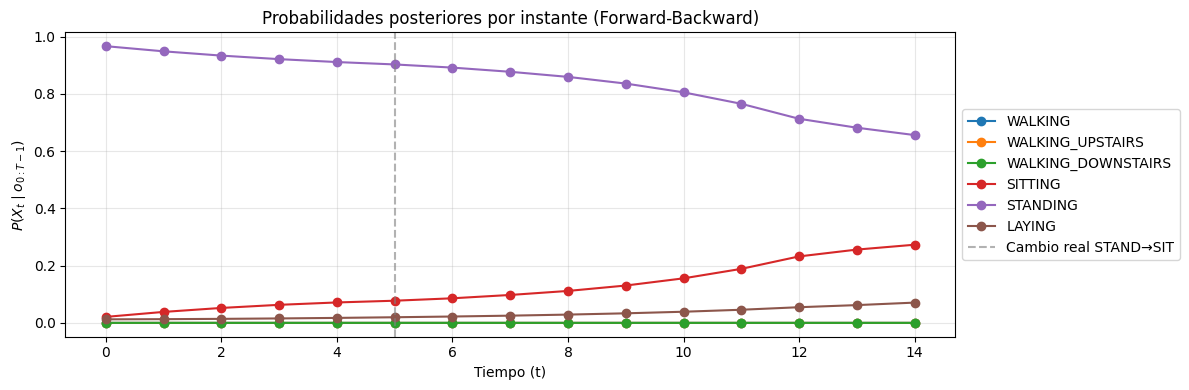

In [60]:
plt.figure(figsize=(12, 4))
for i, state in enumerate(state_names):
    plt.plot(posteriors[:, i], marker="o", label=state)
plt.xlabel("Tiempo (t)")
plt.ylabel(r"$P(X_t \mid o_{0:T-1})$")
plt.title("Probabilidades posteriores por instante (Forward-Backward)")
plt.axvline(x=5, color="gray", linestyle="--", alpha=0.6, label="Cambio real STAND→SIT")
plt.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

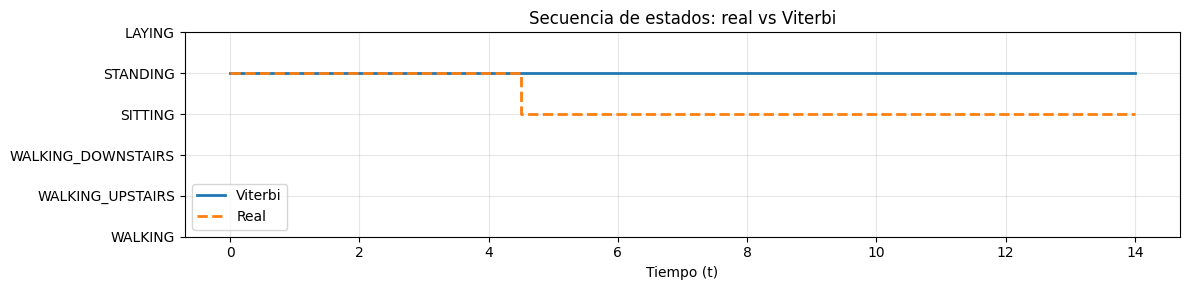

In [61]:
fig, ax = plt.subplots(figsize=(12, 3))
ax.step(range(len(states_viterbi)), states_viterbi,    where="mid", label="Viterbi",    linewidth=2)
ax.step(range(len(true_states_subseq)), true_states_subseq, where="mid", label="Real", linewidth=2, linestyle="--")
ax.set_yticks(range(len(state_names)))
ax.set_yticklabels(state_names)
ax.set_xlabel("Tiempo (t)")
ax.set_title("Secuencia de estados: real vs Viterbi")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## Parte E — Análisis e interpretación de los resultados

### E.1 Sobre la discretización (Parte A)

Los cortes obtenidos con `qcut` para $I_{acc}$ son aproximadamente $[-0.999,\ -0.971,\ -0.269,\ 0.848]$ y para $I_{gyro}$ $[-0.999,\ -0.964,\ -0.412,\ 0.817]$. El primer corte ($\sim -0.97$) es muy bajo: refleja que casi un tercio de las muestras corresponden a actividades estáticas con magnitudes prácticamente nulas (LAYING, SITTING, STANDING), donde tanto la aceleración del cuerpo como la velocidad angular están cerca del mínimo. Esta concentración valida la decisión de usar tertiles equiprobables: una discretización por ancho fijo habría puesto a casi todas las observaciones en un mismo bin "bajo" y dejado vacío el bin "alto".

La distribución conjunta de las 9 observaciones muestra que **dos símbolos (`bajo_alto` y `alto_bajo`) tienen frecuencia exactamente cero**. Esto ocurre porque las magnitudes de aceleración y de giro están físicamente correlacionadas: cuando una persona está quieta, ambas son bajas; cuando camina o se mueve, ambas suben. Combinaciones como aceleración baja con giro alto no aparecen en los datos. Por eso fue necesario aplicar suavizado de Laplace antes de pasar las matrices a `hmmlearn`.

### E.2 Sobre la estimación de parámetros (Parte B)

- **Vector inicial $\pi$.** Antes del suavizado, el conteo crudo es $\pi = [0, 0, 0, 0, 1, 0]$: los **30 sujetos comienzan su secuencia en STANDING**. Esto no es una propiedad genuina de la dinámica del HMM, sino del **protocolo del experimento**: todos los voluntarios fueron grabados iniciando en posición de pie. Después del suavizado, $\pi$ asigna $\sim 0.86$ a STANDING y $\sim 0.028$ a cada otra actividad, lo que permite que una secuencia que no comienza en STANDING tenga probabilidad no nula.

- **Matriz de transición $A$.** Es marcadamente **diagonal-dominante**: las auto-transiciones rondan el 0.94–0.97 y las transiciones entre actividades son $\leq 5\%$. Esto **no significa** que las personas casi nunca cambien de actividad, sino que el dataset original está **organizado por actividad dentro de cada sujeto** (cada bloque de filas corresponde a una sesión continua de una misma actividad). Las "transiciones" capturadas por $A$ son en realidad las uniones entre los bloques sucesivos en que se grabaron las distintas actividades del sujeto. Esta es una limitación importante del modelo: no captura dinámica fisiológica real, sino la estructura de cómo se segmentaron los datos.

  Otro punto a notar: las transiciones entre las actividades activas (WALKING ↔ SITTING, etc.) son cero o casi cero en el conteo crudo, porque entre cada actividad hubo descansos. El suavizado las pone en $\sim 0.005$ para que sigan siendo poco probables pero posibles.

- **Matriz de emisión $B$.** Es altamente coherente con la fisiología:
  - Las **actividades estáticas** (SITTING, STANDING, LAYING) emiten preferentemente `bajo_bajo` ($\sim 0.50$–$0.59$) y `medio_medio` ($\sim 0.28$–$0.39$). Magnitudes pequeñas, como se espera.
  - Las **actividades de caminata** emiten preferentemente `alto_alto` (WALKING_DOWNSTAIRS llega a $\sim 0.86$). Aquí la diferencia entre las tres caminatas es sutil: las tres concentran probabilidad en `alto_alto` y `medio_medio`, lo que **anticipa que el modelo tendrá dificultad para distinguir entre ellas** sólo a partir de estos dos índices.

### E.3 Sobre Forward-Backward y las consultas (Parte C)

La log-probabilidad de la subsecuencia es $\approx -16.68$, equivalente a $P(o_{0:14}) \approx 5.7 \times 10^{-8}$. Es un valor pequeño en magnitud absoluta pero razonable para una secuencia de 15 observaciones discretas con 9 símbolos.

Las consultas muestran una **transición posterior progresiva**: en $t=0$ el modelo está fuertemente convencido de STANDING ($\sim 0.97$, dominado por $\pi$). A medida que avanza el tiempo, la probabilidad de STANDING se erosiona lentamente porque la observación `bajo_bajo` es compatible tanto con STANDING como con SITTING y LAYING. En $t=14$, después de varias observaciones `medio_medio` (típicas de SITTING), el modelo ha repartido la masa entre STANDING ($\sim 0.66$) y SITTING ($\sim 0.27$). Aun así, **STANDING sigue siendo el más probable en todos los instantes del marginal**, debido al peso de $\pi$ y de las auto-transiciones.

Es importante notar que **el marginal posterior nunca llega a SITTING**, pese a que el estado real es SITTING desde $t=5$. Esto refleja una limitación del modelo: el costo de transitar de STANDING a SITTING ($\approx 0.03$) es alto en relación a la cantidad de evidencia que aportan unas pocas observaciones `medio_medio`.

### E.4 Sobre Viterbi (Parte D)

Viterbi devuelve **STANDING en los 15 instantes**, con $\log P(\text{camino}) \approx -17.10$ (probabilidad $\approx 3.7 \times 10^{-8}$). Como se anticipó arriba: aunque el sujeto realmente cambió de STANDING a SITTING en $t=5$, el camino que minimiza la pérdida bajo el modelo es no transitar nunca, porque el "costo" multiplicativo de cruzar a SITTING (factor $0.03$) supera el beneficio de explicar mejor las observaciones `medio_medio` con una emisión más alta.

**Comparando ambas probabilidades**:
- $\log P(\text{obs}) \approx -16.68$ (suma sobre todos los caminos, vía Forward).
- $\log P(\text{camino Viterbi}) \approx -17.10$.

La diferencia ($\sim 0.42$) es positiva y pequeña, lo que confirma que **un único camino concentra la mayor parte de la masa**: $P(\text{Viterbi}) / P(\text{obs}) \approx e^{-0.42} \approx 0.65$. Es decir, el camino Viterbi explica $\sim 65\%$ de la probabilidad total de la secuencia observada. Esto es coherente con un modelo cuyas auto-transiciones dominan: hay pocos caminos relevantes alternativos.

### E.5 Conclusiones generales

1. **El modelo aprende correctamente la estructura estática del dataset**: emisiones coherentes con la fisiología, auto-transiciones dominantes, $\pi$ que refleja el protocolo experimental.
2. **No aprende dinámica real entre actividades** porque los datos no son una grabación continua, sino bloques separados por actividad. Una matriz $A$ aprendida así es útil para clasificar "en qué actividad está el sujeto en este instante" cuando ya hay evidencia previa en esa actividad, pero subestima sistemáticamente las transiciones.
3. **Discriminar entre las tres caminatas** (WALKING / WALKING_UPSTAIRS / WALKING_DOWNSTAIRS) y entre las tres estáticas (SITTING / STANDING / LAYING) **es difícil con sólo 9 observaciones derivadas de dos índices**. Para un HMM con buena precisión de decodificación habría que (a) aumentar la cardinalidad del alfabeto observable (más bins, o más índices), o (b) usar emisiones gaussianas multivariadas (`GaussianHMM`) sobre el vector de features completo.
4. **El suavizado de Laplace fue clave**: sin él, varias filas de $B$ tendrían columnas en cero (símbolos no vistos) y cualquier subsecuencia que los contuviera tendría probabilidad cero. Es un costo bajo (cambio de probabilidades del orden del 1%) por una robustez sustancial.

se utilizo ia para el formato de las formulas utilizadas

---